# Overload, decision time and a search model

This notebook follows `01_baseline_and_h1.ipynb` and adds the three analyses the AAMAS paper did not have.

1. **Where were people overloaded?** The study asked six questions after every choice. We test whether they measure one thing and locate overload display by display.
2. **Does each model's work explain how long people took?** We fit each model's time law to people's decision times.
3. **Can a model that searches predict choices as well, and foresee time and overload?** We propose a one parameter search model, sample until return, and compare it with every established model on choices, time and premonition of overload.

Every model has one free parameter and the designers' fixed rubric weights, and every prediction is held out, each display predicted from fits to the other displays of its task. These are the development data, so every result here is exploratory, and the claims are tested on open data in the confirmatory step that follows. Every number below was verified twice, by a second run and by an independent implementation written blind from a brief (`verification/`).

**Colab.** Run the cells in order. The first cell clones the repository if it is not already in `/content`. Saved results are shown without the development data. To recompute, upload `Updated_Choice_Overload.csv` to `/content` and set `RECOMPUTE = True` (a few seconds for the overload index and about fifteen minutes for the model analyses with two processes).

In [1]:
import os, sys, json, subprocess, zipfile
from pathlib import Path

REPO = Path(os.environ.get("OVERLOAD_REPO", "/content/overload-prediction"))
DATA = Path(os.environ.get("OVERLOAD_DATA", "/content/Updated_Choice_Overload.csv"))
INDEPENDENT = Path(os.environ.get("OVERLOAD_INDEPENDENT", ""))  # optional, a fresh run of the independent code
RECOMPUTE = False
JOBS = 2

if not REPO.exists():
    if Path("/content/overload-prediction.zip").exists():
        zipfile.ZipFile("/content/overload-prediction.zip").extractall("/content")
    else:
        subprocess.run(["git", "clone", "--depth", "1", "https://github.com/ucchol/overload-prediction.git", str(REPO)],
                       check=True)
sys.path.insert(0, str(REPO / "src"))
os.chdir(REPO)
HAVE_DATA = DATA.exists()

import numpy as np
from IPython.display import Image, Markdown, display
import overload
from overload.engine import plan_digest
print("package", overload.__version__, "| plan digest", plan_digest()[:16])
print("development data", "found" if HAVE_DATA else "not found, saved results are shown")


def section(text, start, stop=None):
    # the part of a markdown report from the heading start up to the heading stop
    a = text.index(start)
    return text[a : text.index(stop, a + 1)] if stop else text[a:]

package 0.1.0 | plan digest 876dbadf8f6d0f54
development data found


## 1. Where were people overloaded?

**Question.** Do the six post-trial questions measure one thing, and which displays raised it?

**Why it matters.** Overload is what the paper must foresee, so we first need a trustworthy measure and a map of where it occurred. The classic test compares one small and one large set between people. Here every person rated all twelve displays, so overload can be located display by display, against each person's own baseline.

**How.**
- The six answers run from 1 to 5. They are aligned so that a higher value always means more overloaded, with satisfaction and certainty reversed.
- Question 6 asks "How uncertain are you about choosing the best option?" while its printed anchors run from very uncertain (1) to very certain (5). Participants answered it as an uncertainty question. Their answers fell with satisfaction and certainty and rose with confusion, frustration and complexity, so it is kept as worded.
- The overload index is the mean of the six aligned answers, in scale points. A display overloaded people when its index was clearly above their own average over all twelve displays.
- Regret is 100 minus the designers' score of the chosen option, so 0 means a best option was chosen. Time is the geometric mean of the seconds on the choice page.
- Intervals come from 1000 resamples of participants. A star marks a difference whose percentile and basic intervals both exclude zero.

# Overload index, development data (exploratory)

## Do the six questions measure one thing?

- Cronbach's alpha within participants 0.87 [0.84, 0.90], over all answers 0.89.
- The first principal component carries 62% of the within participant variance.
- Question 6 against the other answers, raw and within participants: satisfied -0.56, certain -0.57, confused +0.53, frustrated +0.53, complex +0.73.

## Where were people overloaded?

| Trial | Options | Information | Overload index | Against own average | Regret | Best chosen, % | Time, s |
|---|---|---|---|---|---|---|---|
| T1_L8 | 8 | low | 2.19 [2.04, 2.35] | +0.05 [-0.05, 0.14] | 29.4 [25.2, 33.8] | 17 | 42 [35, 50] |
| T2_H8 | 8 | high | 2.27 [2.08, 2.45] | +0.13 [-0.01, 0.25] | 15.7 [10.9, 20.8] | 32 | 50 [42, 58] |
| T3_L16 | 16 | low | 2.43 [2.24, 2.61] | +0.29 [0.18, 0.40] * | 18.8 [12.6, 26.2] | 75 | 52 [45, 60] |
| T4_H16 | 16 | high | 2.28 [2.10, 2.46] | +0.14 [0.02, 0.26] * | 28.3 [23.7, 32.9] | 11 | 71 [60, 85] |
| T5_L32 | 32 | low | 2.65 [2.46, 2.84] | +0.50 [0.38, 0.63] * | 31.2 [23.6, 38.2] | 55 | 68 [57, 81] |
| T6_H32 | 32 | high | 2.46 [2.28, 2.64] | +0.32 [0.20, 0.45] * | 26.5 [22.0, 31.3] | 14 | 70 [59, 85] |
| LT1_L8 | 8 | low | 1.81 [1.68, 1.96] | -0.33 [-0.42, -0.24] * | 22.5 [18.6, 26.6] | 29 | 29 [24, 34] |
| LT2_H8 | 8 | high | 1.93 [1.78, 2.08] | -0.21 [-0.32, -0.10] * | 28.5 [24.7, 32.5] | 28 | 35 [29, 42] |
| LT3_L16 | 16 | low | 1.90 [1.76, 2.06] | -0.24 [-0.34, -0.12] * | 28.3 [24.4, 32.1] | 11 | 33 [28, 39] |
| LT4_H16 | 16 | high | 1.84 [1.68, 1.99] | -0.30 [-0.41, -0.20] * | 21.1 [16.4, 26.0] | 44 | 40 [34, 48] |
| LT5_L32 | 32 | low | 2.02 [1.84, 2.20] | -0.12 [-0.25, 0.01] | 15.2 [11.4, 19.1] | 31 | 37 [32, 43] |
| LT6_H32 | 30 | high | 1.91 [1.75, 2.07] | -0.23 [-0.35, -0.12] * | 14.6 [10.4, 18.7] | 33 | 36 [30, 44] |

## More options and more information

| Task | Measure | 32 minus 8 options | Full minus brief |
|---|---|---|---|
| file | overload (scale points) | +0.33 [0.21, 0.45] * | -0.09 [-0.17, 0.01] |
| file | regret (points) | +6.3 [0.8, 11.5] * | -3.0 [-6.9, 1.3] |
| file | logtime (percent time) | +51.5 [32.0, 74.2] * | +19.2 [7.8, 31.8] * |
| laptop | overload (scale points) | +0.09 [-0.03, 0.21] | -0.02 [-0.09, 0.05] |
| laptop | regret (points) | -10.6 [-14.7, -7.0] * | -0.6 [-3.7, 2.6] |
| laptop | logtime (percent time) | +15.4 [4.6, 27.9] * | +13.6 [3.2, 24.7] * |

## Feelings, errors and effort (within participant and trial correlations)

| | Overload and regret | Overload and log time | Regret and log time |
|---|---|---|---|
| file | +0.05 [-0.04, 0.15] | +0.20 [0.11, 0.28] * | +0.19 [0.06, 0.32] * |
| laptop | +0.13 [0.03, 0.24] * | +0.15 [0.06, 0.24] * | +0.05 [-0.06, 0.15] |
| both | +0.13 [0.06, 0.20] * | +0.08 [0.01, 0.16] * | +0.04 [-0.05, 0.14] |

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a difference or correlation whose percentile and basic intervals both exclude zero. The overload index runs from 1 (none) to 5 (strong). Time is the geometric mean on the choice page. Development data, exploratory.


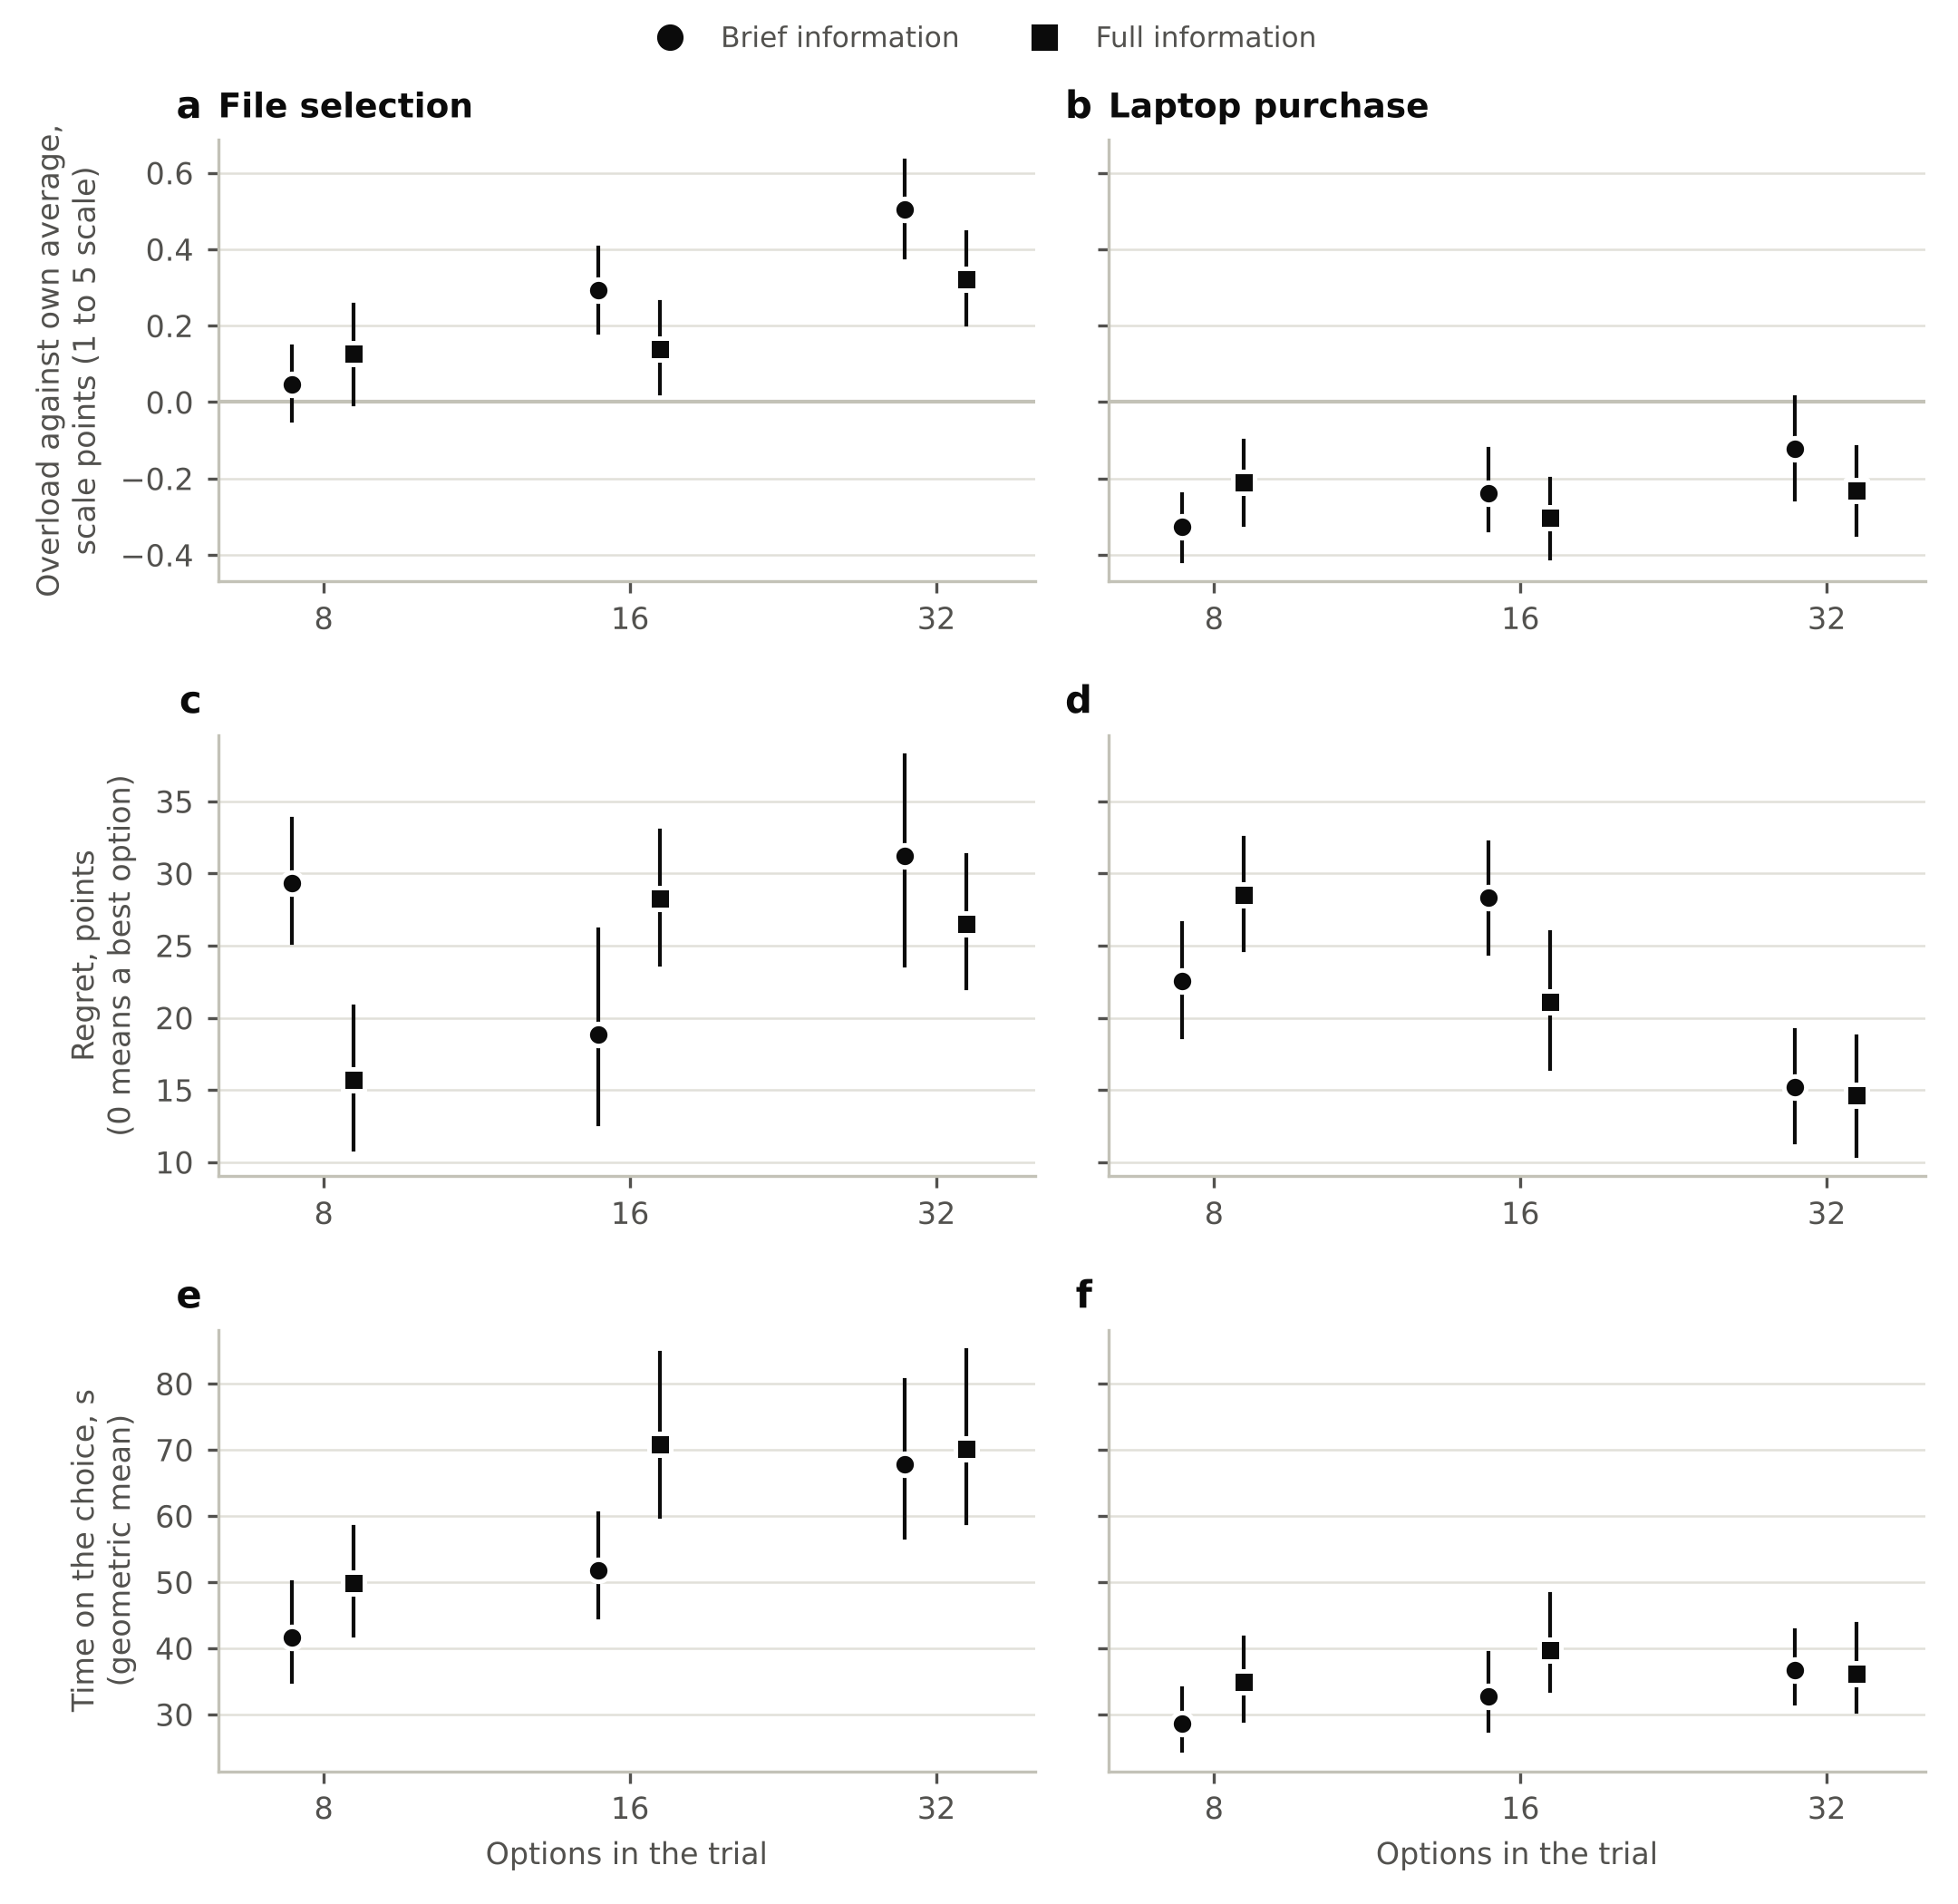

In [2]:
from overload.experiments import overload_index
from overload.figures import figure_overload
out = REPO / "results" / "overload"
if HAVE_DATA and (RECOMPUTE or not (out / "summary.json").exists()):
    overload_index.run(DATA, out, replicates=1000)
over = json.loads((out / "summary.json").read_text())
figure_overload(over, out / "fig_overload")
display(Markdown((out / "table_overload.md").read_text()))
display(Image(filename=str(out / "fig_overload.png"), width=820))

**Findings.**

1. The six questions measured one thing. Cronbach's alpha within participants was 0.87 [0.84, 0.90], and one component carried 62 percent of the variance.
2. File displays overloaded people more as they grew. Against people's own average, overload rose from +0.05 and +0.13 scale points at 8 files to +0.50 and +0.32 at 32 files, a rise of 0.33 [0.21, 0.45]. Choices also took 52 percent longer [32, 74].
3. Laptop displays never overloaded people. Every laptop display stayed below people's own average, even at 32 laptops (+0.09 [-0.03, 0.21] from 8 to 32 laptops). Choices took only 15 percent longer [5, 28], and they got better, with regret falling by 10.6 points [7.0, 14.7].
4. More information per option did not add overload in either task (-0.09 and -0.02 scale points), although it slowed choices by 19 and 14 percent.
5. Feeling overloaded went with taking longer. On a display where a person felt more overloaded than usual, compared with others on the same display, they also took longer (correlations +0.20 for files and +0.15 for laptops, both clear). The link with regret was weak (+0.05 and +0.13).

**Message.** Overload is not a law of set size. The same people were overloaded by large file displays and not by large laptop displays. A premonition of overload must read the display, not count its options.

## 2. Does each model's work explain how long people took?

**Question.** Each model's algorithm needs a certain amount of work on each display. Does that work explain how long people took?

**Why it matters.** A model that describes how people decide should also predict how long they take. Time is evidence about the process that choices alone cannot give.

**How.** Each model is written as the elementary steps its algorithm needs (Payne, Bettman and Johnson 1993). One step is reading one attribute value of one option and using it once, adding it into the option's value or comparing it with a rival's.
- CL and QR weigh every value, n m steps for n options and m attributes.
- DbS and MLBA compare every option with every rival on every attribute, n (n - 1) m steps.
- Elimination by aspects checks one aspect across the options still in play, until one option is left.
- Sample until return (Section 3) reads the m attributes of each option it looks at.

Each model's time law, a start up time plus a time per step, both nonnegative, is fitted to people's typical decision time on each display.
- **In sample**, on all six displays of a task, the fit says how much of people's time the model's work can carry.
- **Held out**, the two constants are fitted on five displays and predict the sixth, and the typical error is compared with a forecast that ignores the display.

An earlier version of this section divided people's time by each model's steps and asked how fast each step would have to be. That is not a fit. It assumes every second goes to the model's steps, and the fitted laws below show that most of it does not, so it was withdrawn.

## 2. Time, file

Time law fitted to the typical seconds of all six trials.

| Model | Effort, steps per trial | Start up time, s | Time per step, ms | Variation explained |
|---|---|---|---|---|
| People, seconds | 42, 50, 52, 71, 68, 70 | | | |
| QR | 8, 32, 16, 64, 32, 128 | 49.1 | 205 | 0.53 |
| CL | 8, 32, 16, 64, 32, 128 | 49.1 | 205 | 0.53 |
| DbS_avg | 56, 224, 240, 960, 992, 3968 | 52.6 | 5.69 | 0.45 |
| MLBA_avg | 56, 224, 240, 960, 992, 3968 | 52.6 | 5.69 | 0.45 |
| EBA | 13, 121, 25, 64, 32, 501 | 54.9 | 30.4 | 0.21 |
| SR | 4, 16, 5, 21, 7, 29 | 47.6 | 797 | 0.42 |
| SR_DbS | 4, 16, 5, 21, 7, 29 | 47.3 | 817 | 0.43 |
| Accept_read | 5, 19, 5, 37, 4, 10 | 53.3 | 401 | 0.17 |

Held out predicted seconds, constants fitted on the other five trials.

| Model | T1_L8 | T2_H8 | T3_L16 | T4_H16 | T5_L32 | T6_H32 | Typical error, % | Minus constant (log) |
|---|---|---|---|---|---|---|---|---|
| QR | 55 | 57 | 53 | 60 | 53 | 103 | 22.7 [10.1, 37.5] * | -0.023 [-0.115, 0.078] |
| CL | 55 | 57 | 53 | 60 | 53 | 103 | 22.7 [10.1, 37.5] * | -0.023 [-0.115, 0.078] |
| DbS_avg | 57 | 55 | 55 | 55 | 56 | 152 | 32.0 [16.0, 48.7] * | +0.050 [-0.057, 0.150] |
| MLBA_avg | 57 | 55 | 55 | 55 | 56 | 152 | 32.0 [16.0, 48.7] * | +0.050 [-0.057, 0.150] |
| EBA | 60 | 60 | 57 | 54 | 53 | 68 | 22.3 [15.6, 33.4] * | -0.026 [-0.052, 0.047] |
| SR | 56 | 63 | 52 | 62 | 48 | 73 | 18.8 [12.5, 32.3] * | -0.055 [-0.087, 0.037] |
| SR_DbS | 56 | 63 | 52 | 62 | 48 | 73 | 18.6 [12.2, 32.0] * | -0.057 [-0.091, 0.036] |
| Accept_read | 60 | 63 | 57 | 56 | 51 | 55 | 27.8 [18.1, 36.0] * | +0.017 [-0.012, 0.034] |
| constant | 62 | 60 | 60 | 56 | 57 | 56 | 25.6 [18.0, 32.9] * |  |

## 2. Time, laptop

Time law fitted to the typical seconds of all six trials.

| Model | Effort, steps per trial | Start up time, s | Time per step, ms | Variation explained |
|---|---|---|---|---|
| People, seconds | 29, 35, 33, 40, 37, 36 | | | |
| QR | 24, 48, 48, 96, 96, 180 | 31.3 | 42.4 | 0.39 |
| CL | 24, 48, 48, 96, 96, 180 | 31.3 | 42.4 | 0.39 |
| DbS_avg | 168, 336, 720, 1440, 2976, 5220 | 33.1 | 0.917 | 0.22 |
| MLBA_avg | 168, 336, 720, 1440, 2976, 5220 | 33.1 | 0.917 | 0.22 |
| EBA | 31, 19, 70, 119, 148, 241 | 32.1 | 25.2 | 0.30 |
| SR | 11, 24, 16, 30, 21, 40 | 28.4 | 272 | 0.52 |
| SR_DbS | 11, 23, 16, 28, 21, 39 | 28.3 | 280 | 0.50 |
| Accept_read | 22, 32, 16, 51, 21, 40 | 28.5 | 207 | 0.50 |

Held out predicted seconds, constants fitted on the other five trials.

| Model | LT1_L8 | LT2_H8 | LT3_L16 | LT4_H16 | LT5_L32 | LT6_H32 | Typical error, % | Minus constant (log) |
|---|---|---|---|---|---|---|---|---|
| QR | 35 | 33 | 34 | 34 | 35 | 49 | 13.5 [6.2, 26.3] * | +0.029 [-0.033, 0.074] |
| CL | 35 | 33 | 34 | 34 | 35 | 49 | 13.5 [6.2, 26.3] * | +0.029 [-0.033, 0.074] |
| DbS_avg | 35 | 33 | 34 | 33 | 36 | 44 | 12.5 [6.5, 24.6] * | +0.021 [-0.026, 0.060] |
| MLBA_avg | 35 | 33 | 34 | 33 | 36 | 44 | 12.5 [6.5, 24.6] * | +0.021 [-0.026, 0.060] |
| EBA | 35 | 31 | 34 | 34 | 36 | 43 | 12.5 [6.5, 24.2] * | +0.020 [-0.029, 0.056] |
| SR | 34 | 35 | 33 | 35 | 34 | 46 | 10.8 [4.9, 23.6] | +0.006 [-0.057, 0.054] |
| SR_DbS | 34 | 35 | 33 | 35 | 34 | 46 | 11.1 [5.2, 24.1] | +0.008 [-0.056, 0.058] |
| Accept_read | 35 | 35 | 31 | 38 | 32 | 37 | 8.2 [5.3, 18.7] | -0.018 [-0.059, 0.036] |
| constant | 36 | 35 | 35 | 34 | 34 | 34 | 10.2 [6.5, 18.4] * |  |



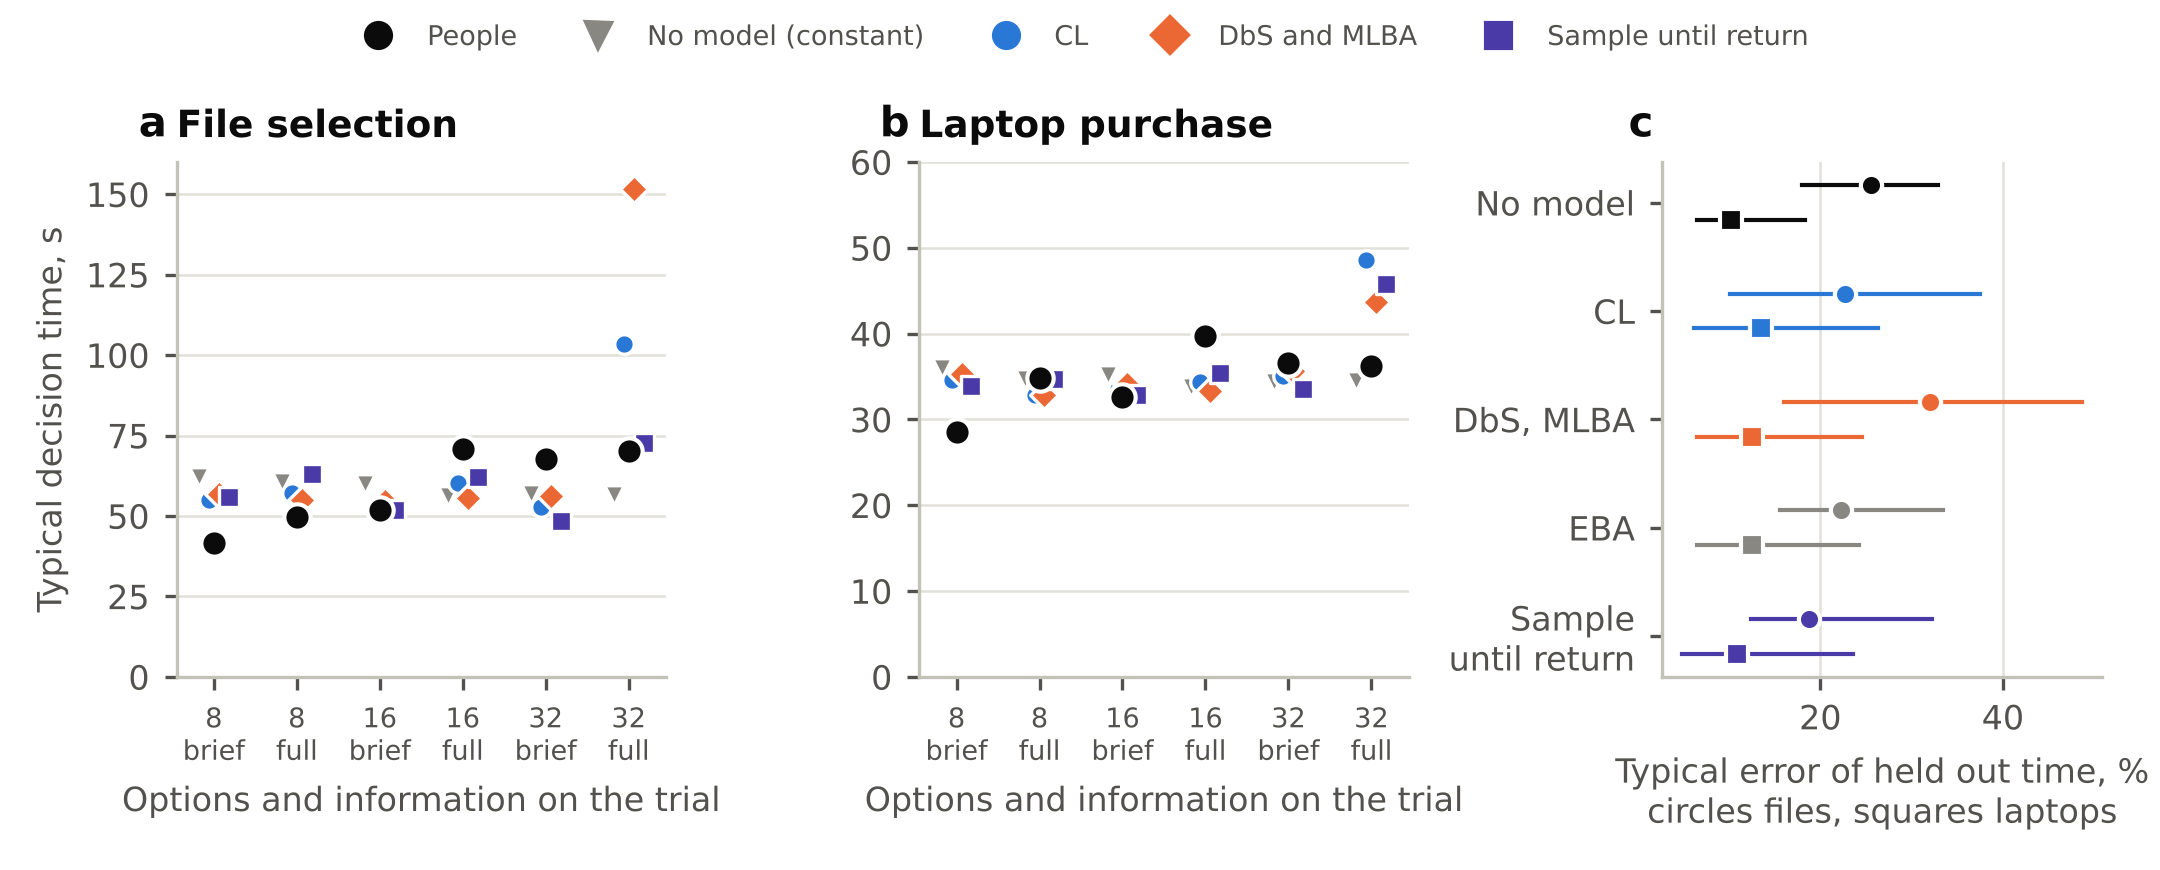

In [3]:
from overload.experiments import process_dev
from overload.figures import figure_time
out = REPO / "results" / "process_dev"
if HAVE_DATA and (RECOMPUTE or not (out / "summary.json").exists()):
    process_dev.run(DATA, out, replicates=1000, jobs=JOBS)
proc = json.loads((out / "summary.json").read_text())
tables = (out / "tables.md").read_text()
display(Markdown(section(tables, "## 2. Time, file", "## 3. Premonition")))
figure_time(proc, out / "fig_time")
display(Image(filename=str(out / "fig_time.png"), width=900))

**Findings.**

1. People's times varied little across displays. A laptop choice took 29 to 40 seconds whatever the size of the display, and a file choice 42 to 71 seconds.
2. No model's work fitted these times. Fitted to all six displays of a task, every time law put most of people's time into the start up constant, 47 to 55 seconds for files and 28 to 33 for laptops, and its two constants explained 17 to 53 percent of the variation across the six displays.
3. Held out, no model predicted time better than a forecast that ignores the display. The typical error of sample until return was 18.8 percent for files and 10.8 for laptops, against 25.6 and 10.2 for the constant, and CL, DbS and MLBA did no better. The laws also overshot the largest full display, where a model's work jumps (for files CL predicted 103 seconds and DbS 152, against 70 observed).

**Message.** On these displays, how long people took is not explained by the work of any model, ours included. Time cannot rank the models here, so the comparison rests on choices and, in the confirmatory data, on how people search.

## 3. A model that searches. Sample until return

**The idea.** Attention moves from option to option. It is drawn to attractive options, with probability proportional to exp(lambda v), where v are the same rubric values CL uses and lambda is the one free parameter. When attention comes back to an option it has already visited, that option is chosen.

**Why this model.**
- In choices among many options, attention is drawn to valuable options (Krajbich and colleagues), and coming back to an option is a natural sign that it stands out.
- It needs no knowledge of the best option and no threshold, only one sensitivity, like CL.
- Everything follows in closed form. With q = softmax(lambda v), the chance that option i is chosen is P(i) = q_i² ∫ t e^(-t) ∏_(j≠i) (1 + q_j t) dt, and the expected number of looks is E[looks] = ∫ e^(-t) ∏_j (1 + q_j t) dt, both integrals from 0 to infinity (`overload.search`).
- With equal options this is the birthday problem. The expected number of looks grows with the square root of the number of options, so search grows far more slowly than the display.
- When one option stands out, attention keeps coming back to it and the decision is quick. When many options are about equally attractive, looks spread over them and the decision runs long, which is where overload should appear.

**A rejected alternative.** Accept in reading order inspects options in the listed order and accepts each with a probability that rises toward the best on display. It is reported beside the others because it fails, which shows that searching is not enough by itself. The order and the stopping rule matter.

The first cell checks the closed forms against a simulation of the process and shows the square root law. It needs no data.

In [4]:
from scipy.special import softmax
from overload.search import race_length, race_probabilities, sample_until_return

rng = np.random.default_rng(1)
v = rng.normal(size=9)
q = softmax(1.2 * v)
draws = rng.choice(q.size, size=(40000, q.size + 1), p=q)
wins, looks = np.zeros(q.size), 0
for row in draws:
    seen = set()
    for t, x in enumerate(row):
        if x in seen:
            wins[x] += 1
            looks += t + 1
            break
        seen.add(x)
print("largest gap between simulated and closed form choice shares", round(float(np.abs(wins / 40000 - race_probabilities(q)).max()), 4))
print("expected looks, simulated", round(looks / 40000, 3), "closed form", round(race_length(q), 3))
print()
for n in (8, 16, 32, 64, 128):
    e = race_length(np.ones(n) / n)
    print(f"{n:4d} equal options, expected looks {e:5.2f}, looks / sqrt(n) {e / np.sqrt(n):.2f}")

largest gap between simulated and closed form choice shares 0.0035
expected looks, simulated 4.111 closed form 4.103

   8 equal options, expected looks  4.25, looks / sqrt(n) 1.50
  16 equal options, expected looks  5.70, looks / sqrt(n) 1.43
  32 equal options, expected looks  7.77, looks / sqrt(n) 1.37
  64 equal options, expected looks 10.71, looks / sqrt(n) 1.34
 128 equal options, expected looks 14.86, looks / sqrt(n) 1.31


## 1. Choices, held out completeness (%)

| Model | Files | Laptops |
|---|---|---|
| QR | 21.9 [14.3, 30.1] * | 47.2 [36.4, 58.3] * |
| CL | 29.5 [20.2, 39.2] * | 55.4 [43.1, 67.9] * |
| DbS_avg | 32.1 [22.4, 42.2] * | 59.3 [46.0, 72.6] * |
| MLBA_avg | 31.4 [22.2, 41.3] * | 59.7 [46.1, 73.6] * |
| DbS_sum | 23.9 [16.1, 32.0] * | 57.9 [43.4, 73.3] * |
| MLBA_sum | 22.6 [15.0, 30.2] * | 56.9 [42.6, 71.7] * |
| EBA | -2.7 [-8.1, 1.9] | 14.0 [8.0, 20.6] * |
| SR | 29.4 [20.2, 39.1] * | 56.2 [43.9, 68.9] * |
| SR_DbS | 31.9 [22.2, 42.1] * | 59.7 [46.2, 73.1] * |
| SR_MLBA | 31.2 [22.0, 41.2] * | 59.7 [46.0, 73.7] * |
| Accept_read | -39.5 [-70.1, -8.3] * | 27.2 [4.4, 48.8] * |

Same values, different process (points of completeness).

| Contrast | Files | Laptops |
|---|---|---|
| SR-CL | -0.1 [-0.3, 0.2] | +0.8 [0.3, 1.4] * |
| SR_DbS-DbS_avg | -0.2 [-0.5, 0.1] | +0.4 [-0.1, 1.0] |
| SR_MLBA-MLBA_avg | -0.1 [-0.4, 0.2] | +0.0 [-0.4, 0.5] |
| Accept_read-CL | -69.1 [-93.8, -43.5] * | -28.2 [-41.6, -14.3] * |

The search model against the established models (points).

| Contrast | Files | Laptops |
|---|---|---|
| SR-CL | -0.1 [-0.3, 0.2] | +0.8 [0.3, 1.4] * |
| SR-DbS_avg | -2.6 [-4.6, -0.8] * | -3.1 [-5.3, -0.9] * |
| SR-MLBA_avg | -1.9 [-4.7, 0.7] | -3.5 [-7.6, 0.3] |
| SR_DbS-CL | +2.3 [0.5, 4.2] * | +4.3 [1.8, 7.2] * |
| SR_DbS-DbS_avg | -0.2 [-0.5, 0.1] | +0.4 [-0.1, 1.0] |
| SR_DbS-MLBA_avg | +0.5 [-0.6, 1.6] | -0.0 [-1.7, 1.5] |



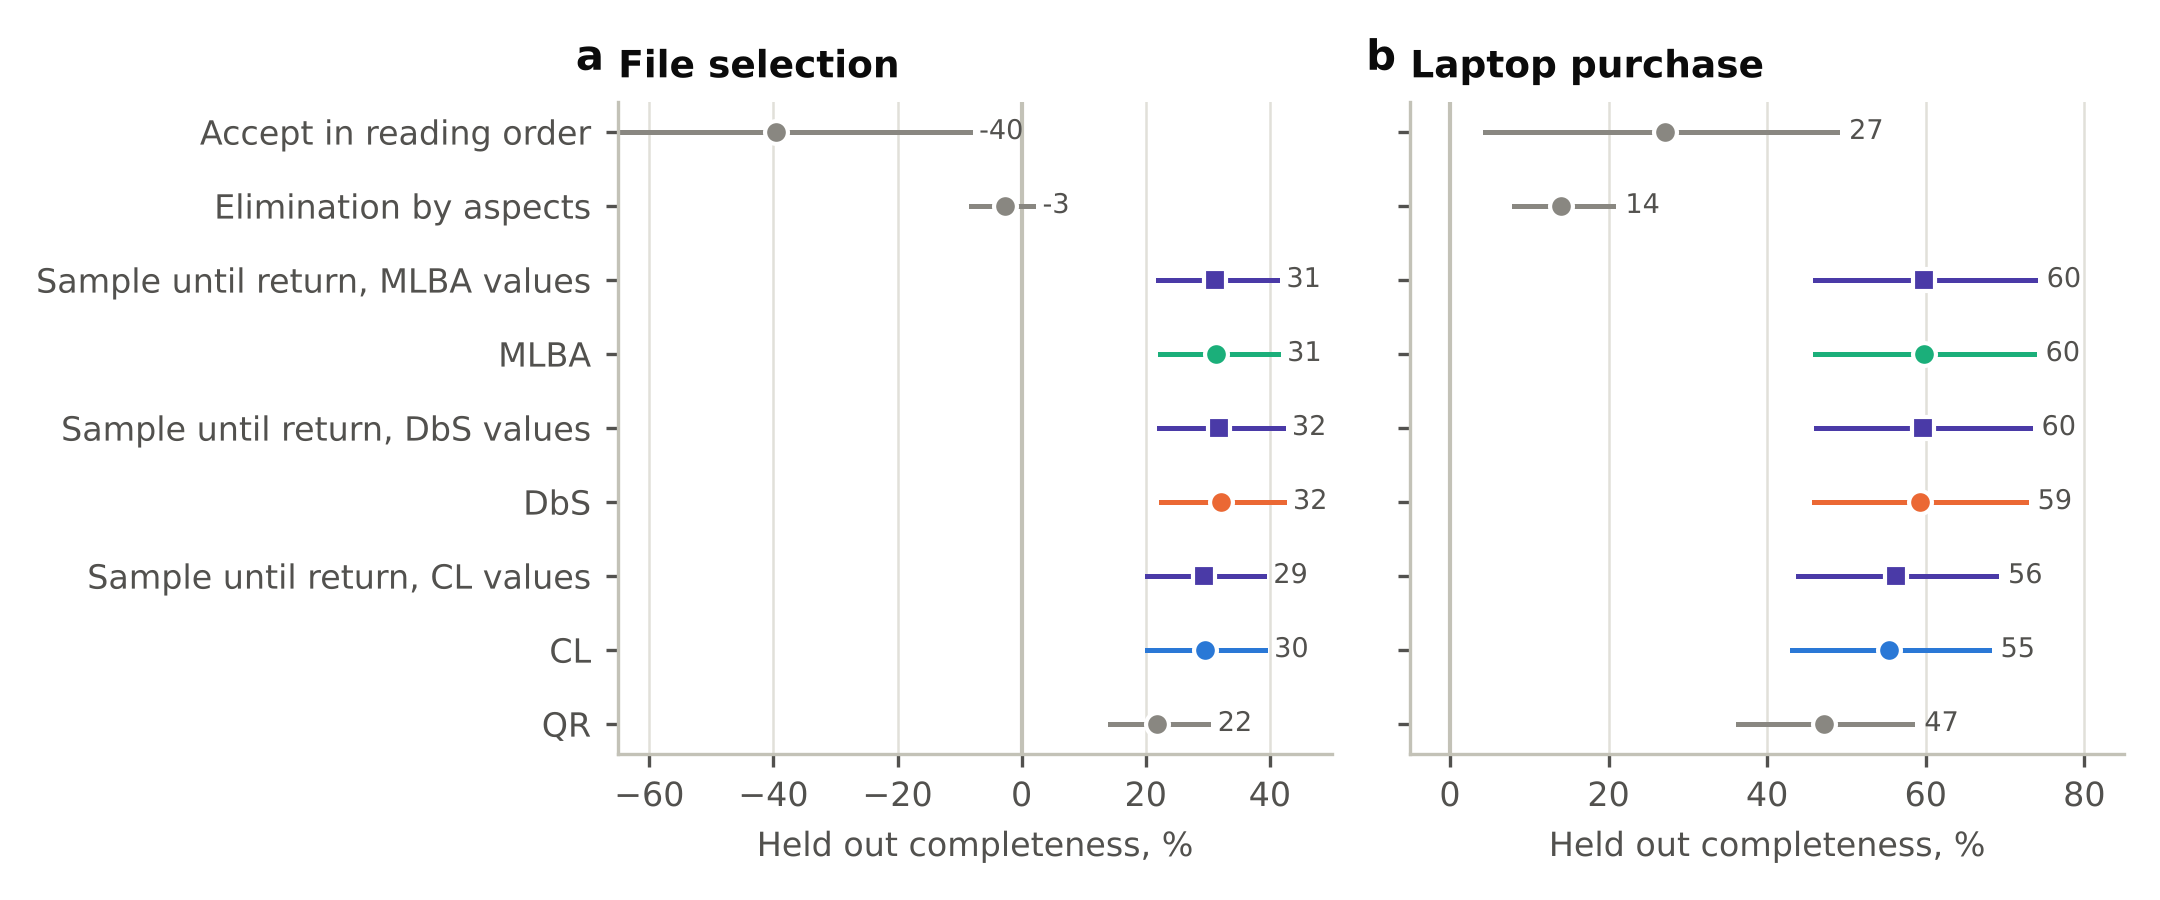

In [5]:
from overload.figures import figure_process_choices
display(Markdown(section(tables, "## 1. Choices", "## 2. Time, file")))
figure_process_choices(proc, out / "fig_choices")
display(Image(filename=str(out / "fig_choices.png"), width=900))

**Findings.**

1. With the same values, searching predicted choices as well as weighing everything. Sample until return on CL values reached 29.4 percent of the attainable for files and 56.2 percent for laptops, against CL's 29.5 and 55.4 (differences -0.1 [-0.3, 0.2] and +0.8 [0.3, 1.4]). On DbS values it reached 31.9 and 59.7 percent, against DbS's 32.1 and 59.3.
2. So the search model matched the best established models, DbS and MLBA, on choices, without beating them.
3. Accept in reading order failed badly (-39.5 percent for files and 27.2 for laptops), as did elimination by aspects (-2.7 and 14.0).

**Message.** Choices cannot tell processes apart. Given the same values, a model that searches and stops predicts the same choices as one that weighs everything. Process models must be judged on how people search, which the development data do not record and the snack data do (Section 7).

## 4. Premonition. Can a model foresee overload before anyone chooses?

**Question.** From the display alone, and fits to other displays, can we tell which displays will overload people and on which they will choose poorly?

**Why it matters.** This is the practical payoff. A designer, a retailer or a defender could check a display before showing it.

**How.** Every forecast is computed from the display's options and from fits to the other displays, never from the display's own choices or answers.
- Feelings. Forecasts are the number of options, the attributes shown, each model's predicted spread of choices (entropy) and the search model's expected number of looks. A forecast is judged by how well it orders the displays by their overload index (rank correlation), and by the error of a held out calibration line against a forecast that ignores the display. This is done within each task and over both tasks together.
- Choice quality. Each model's expected regret, the shortfall of every option weighted by the model's predicted choice probabilities, is compared directly with people's mean regret.

With six displays per task, these rank correlations move in large steps, so they are read as descriptions.

## 3. Premonition, files

Overload index by trial: 2.19, 2.27, 2.43, 2.28, 2.65, 2.46. Constant forecast error 0.161 [0.108, 0.226] *.

| Forecast | Spearman with overload | Held out error, scale points | Minus constant |
|---|---|---|---|
| options | +0.96 [0.60, 0.96] * | 0.109 [0.055, 0.175] * | -0.052 [-0.106, 0.008] |
| attributes | -0.10 [-0.49, 0.10] | 0.180 [0.127, 0.254] * | +0.019 [0.004, 0.045] |
| looks_SR | +0.89 [0.60, 0.94] * | 0.110 [0.058, 0.176] * | -0.050 [-0.104, 0.009] |
| cells | +0.49 [-0.06, 0.52] | 0.170 [0.114, 0.253] * | +0.010 [-0.014, 0.051] |
| entropy_QR | +0.89 [0.43, 0.89] * | 0.113 [0.063, 0.180] * | -0.048 [-0.095, 0.011] |
| entropy_CL | +0.89 [0.60, 0.94] * | 0.107 [0.057, 0.172] * | -0.054 [-0.107, 0.006] |
| entropy_DbS_avg | +0.94 [0.71, 1.00] * | 0.101 [0.052, 0.164] * | -0.060 [-0.113, 0.000] |
| entropy_MLBA_avg | +0.94 [0.71, 1.00] * | 0.097 [0.049, 0.159] * | -0.064 [-0.119, -0.003] * |
| entropy_SR | +0.89 [0.60, 0.94] * | 0.108 [0.057, 0.173] * | -0.053 [-0.106, 0.007] |
| entropy_SR_DbS | +0.94 [0.71, 1.00] * | 0.100 [0.052, 0.163] * | -0.060 [-0.113, 0.000] |
| effort_CL | +0.49 [-0.06, 0.52] | 0.170 [0.114, 0.253] * | +0.010 [-0.014, 0.051] |
| effort_DbS_avg | +0.89 [0.43, 0.89] * | 0.262 [0.152, 0.376] * | +0.101 [0.007, 0.189] * |
| effort_EBA | +0.31 [-0.14, 0.43] | 0.251 [0.128, 0.392] * | +0.091 [0.007, 0.177] * |
| effort_SR | +0.37 [-0.14, 0.43] | 0.205 [0.130, 0.289] * | +0.044 [0.020, 0.066] * |

Regret by trial: 29.4, 15.7, 18.8, 28.3, 31.2, 26.5. Constant forecast error 6.16 [3.98, 8.56] * points.

| Expected regret of | Forecasts by trial | Spearman with regret | Error, points | Minus constant |
|---|---|---|---|---|
| QR | 15.7, 31.5, 17.1, 24.6, 25.7, 33.7 | -0.31 [-0.54, 0.26] | 7.92 [6.11, 10.17] * | +1.76 [-0.38, 4.25] |
| CL | 20.3, 27.7, 16.9, 17.8, 26.3, 31.7 | -0.09 [-0.43, 0.43] | 7.25 [5.50, 9.49] * | +1.09 [-1.08, 3.63] |
| DbS_avg | 18.8, 26.9, 17.2, 19.4, 29.8, 29.2 | +0.31 [-0.14, 0.66] | 6.04 [4.88, 8.43] * | -0.12 [-1.57, 3.04] |
| MLBA_avg | 19.3, 28.0, 18.5, 20.6, 32.4, 28.3 | +0.31 [-0.26, 0.60] | 5.56 [4.73, 8.18] * | -0.61 [-1.74, 2.90] |
| EBA | 29.4, 46.4, 30.2, 37.7, 54.2, 46.8 | +0.14 [-0.37, 0.60] | 15.78 [13.18, 19.09] * | +9.62 [6.63, 12.96] * |
| SR | 20.7, 28.6, 16.8, 18.2, 25.4, 31.2 | -0.09 [-0.43, 0.37] | 7.36 [5.54, 9.60] * | +1.19 [-0.98, 3.64] |
| SR_DbS | 19.2, 27.7, 17.2, 19.7, 29.0, 28.5 | +0.31 [-0.20, 0.60] | 6.11 [4.93, 8.47] * | -0.05 [-1.36, 2.92] |

## 3. Premonition, laptops

Overload index by trial: 1.81, 1.93, 1.90, 1.84, 2.02, 1.91. Constant forecast error 0.061 [0.040, 0.127].

| Forecast | Spearman with overload | Held out error, scale points | Minus constant |
|---|---|---|---|
| options | +0.53 [-0.15, 0.85] | 0.076 [0.036, 0.141] * | +0.015 [-0.044, 0.032] |
| attributes | +0.10 [-0.68, 0.49] | 0.081 [0.047, 0.157] * | +0.020 [-0.001, 0.035] |
| looks_SR | +0.66 [-0.03, 0.94] | 0.071 [0.036, 0.137] * | +0.010 [-0.047, 0.029] |
| cells | +0.44 [-0.35, 0.77] | 0.088 [0.046, 0.154] * | +0.027 [-0.018, 0.047] |
| entropy_QR | +0.37 [-0.31, 0.71] | 0.081 [0.041, 0.146] * | +0.020 [-0.032, 0.037] |
| entropy_CL | +0.66 [-0.03, 0.94] | 0.069 [0.034, 0.133] * | +0.008 [-0.044, 0.028] |
| entropy_DbS_avg | +0.66 [-0.03, 0.94] | 0.064 [0.029, 0.127] * | +0.003 [-0.053, 0.026] |
| entropy_MLBA_avg | +0.66 [0.03, 0.94] * | 0.059 [0.026, 0.122] | -0.002 [-0.062, 0.025] |
| entropy_SR | +0.66 [-0.03, 0.94] | 0.070 [0.033, 0.133] * | +0.009 [-0.044, 0.028] |
| entropy_SR_DbS | +0.66 [-0.03, 0.94] | 0.064 [0.029, 0.127] * | +0.003 [-0.053, 0.026] |
| effort_CL | +0.44 [-0.35, 0.77] | 0.088 [0.046, 0.154] * | +0.027 [-0.018, 0.047] |
| effort_DbS_avg | +0.49 [-0.31, 0.77] | 0.097 [0.046, 0.166] * | +0.036 [-0.008, 0.057] |
| effort_EBA | +0.26 [-0.49, 0.66] | 0.085 [0.044, 0.148] * | +0.024 [-0.016, 0.040] |
| effort_SR | +0.31 [-0.54, 0.60] | 0.076 [0.047, 0.147] * | +0.015 [-0.010, 0.036] |

Regret by trial: 22.5, 28.5, 28.3, 21.1, 15.2, 14.6. Constant forecast error 5.70 [4.45, 7.76] * points.

| Expected regret of | Forecasts by trial | Spearman with regret | Error, points | Minus constant |
|---|---|---|---|---|
| QR | 17.1, 18.9, 15.9, 27.7, 25.4, 25.0 | -0.60 [-0.77, -0.37] * | 9.11 [7.14, 11.00] * | +3.41 [1.72, 3.46] * |
| CL | 14.5, 25.0, 22.5, 21.3, 22.4, 22.5 | +0.20 [-0.20, 0.49] | 5.44 [4.16, 7.47] * | -0.26 [-1.27, 0.11] |
| DbS_avg | 16.0, 26.0, 21.3, 18.1, 23.8, 21.0 | +0.31 [-0.14, 0.37] | 5.68 [4.12, 7.46] * | -0.02 [-1.44, 0.63] |
| MLBA_avg | 19.2, 28.3, 20.7, 16.6, 25.0, 20.1 | +0.37 [-0.09, 0.37] | 5.14 [3.92, 7.13] * | -0.56 [-2.03, 0.81] |
| EBA | 31.4, 41.2, 25.5, 37.7, 33.3, 34.4 | +0.03 [-0.37, 0.26] | 13.13 [11.32, 14.99] * | +7.43 [4.99, 9.17] * |
| SR | 15.5, 25.8, 22.4, 21.4, 21.7, 21.8 | +0.43 [-0.06, 0.66] | 4.95 [3.72, 6.99] * | -0.75 [-1.75, -0.14] |
| SR_DbS | 17.0, 26.6, 21.2, 18.3, 23.2, 20.3 | +0.31 [-0.09, 0.37] | 5.18 [3.66, 6.99] * | -0.52 [-1.89, 0.32] |

## 3. Premonition, both tasks together

Overload index by trial: 2.19, 2.27, 2.43, 2.28, 2.65, 2.46, 1.81, 1.93, 1.90, 1.84, 2.02, 1.91. Constant forecast error 0.260 [0.172, 0.361] *.

| Forecast | Spearman with overload | Held out error, scale points | Minus constant |
|---|---|---|---|
| options | +0.41 [0.22, 0.52] * | 0.287 [0.177, 0.401] * | +0.026 [0.001, 0.038] * |
| attributes | -0.39 [-0.58, -0.30] * | 0.211 [0.149, 0.291] * | -0.049 [-0.084, -0.011] * |
| looks_SR | +0.52 [0.34, 0.63] * | 0.271 [0.167, 0.381] * | +0.011 [-0.013, 0.026] |
| cells | -0.13 [-0.35, -0.05] | 0.263 [0.184, 0.356] * | +0.003 [-0.014, 0.019] |
| entropy_QR | +0.53 [0.31, 0.64] * | 0.257 [0.165, 0.364] * | -0.004 [-0.026, 0.016] |
| entropy_CL | +0.52 [0.34, 0.63] * | 0.259 [0.157, 0.365] * | -0.001 [-0.029, 0.019] |
| entropy_DbS_avg | +0.57 [0.36, 0.71] * | 0.254 [0.155, 0.358] * | -0.006 [-0.036, 0.016] |
| entropy_MLBA_avg | +0.65 [0.38, 0.76] * | 0.249 [0.150, 0.351] * | -0.011 [-0.043, 0.013] |
| entropy_SR | +0.52 [0.34, 0.63] * | 0.257 [0.157, 0.363] * | -0.003 [-0.033, 0.018] |
| entropy_SR_DbS | +0.57 [0.36, 0.72] * | 0.252 [0.154, 0.356] * | -0.008 [-0.038, 0.015] |
| effort_CL | -0.13 [-0.35, -0.05] | 0.263 [0.184, 0.356] * | +0.003 [-0.014, 0.019] |
| effort_DbS_avg | +0.10 [-0.13, 0.19] | 0.289 [0.193, 0.394] * | +0.029 [0.019, 0.041] * |
| effort_EBA | +0.02 [-0.17, 0.15] | 0.322 [0.207, 0.450] * | +0.062 [0.031, 0.091] * |
| effort_SR | -0.27 [-0.50, -0.17] * | 0.243 [0.170, 0.329] * | -0.017 [-0.047, 0.008] |

Regret by trial: 29.4, 15.7, 18.8, 28.3, 31.2, 26.5, 22.5, 28.5, 28.3, 21.1, 15.2, 14.6. Constant forecast error 5.83 [4.67, 7.34] * points.

| Expected regret of | Forecasts by trial | Spearman with regret | Error, points | Minus constant |
|---|---|---|---|---|
| QR | 15.7, 31.5, 17.1, 24.6, 25.7, 33.7, 17.1, 18.9, 15.9, 27.7, 25.4, 25.0 | -0.32 [-0.55, 0.10] | 8.52 [7.25, 10.01] * | +2.68 [1.38, 3.98] * |
| CL | 20.3, 27.7, 16.9, 17.8, 26.3, 31.7, 14.5, 25.0, 22.5, 21.3, 22.4, 22.5 | +0.07 [-0.21, 0.39] | 6.35 [5.34, 7.89] * | +0.51 [-0.70, 2.01] |
| DbS_avg | 18.8, 26.9, 17.2, 19.4, 29.8, 29.2, 16.0, 26.0, 21.3, 18.1, 23.8, 21.0 | +0.22 [-0.08, 0.47] | 5.86 [5.02, 7.43] * | +0.03 [-1.16, 1.68] |
| MLBA_avg | 19.3, 28.0, 18.5, 20.6, 32.4, 28.3, 19.2, 28.3, 20.7, 16.6, 25.0, 20.1 | +0.36 [-0.04, 0.50] | 5.35 [4.82, 7.16] * | -0.49 [-1.50, 1.53] |
| EBA | 29.4, 46.4, 30.2, 37.7, 54.2, 46.8, 31.4, 41.2, 25.5, 37.7, 33.3, 34.4 | +0.09 [-0.19, 0.37] | 14.46 [12.84, 16.34] * | +8.62 [6.55, 10.61] * |
| SR | 20.7, 28.6, 16.8, 18.2, 25.4, 31.2, 15.5, 25.8, 22.4, 21.4, 21.7, 21.8 | +0.11 [-0.17, 0.48] | 6.15 [5.16, 7.70] * | +0.32 [-0.93, 1.81] |
| SR_DbS | 19.2, 27.7, 17.2, 19.7, 29.0, 28.5, 17.0, 26.6, 21.2, 18.3, 23.2, 20.3 | +0.22 [-0.08, 0.49] | 5.65 [4.86, 7.18] * | -0.19 [-1.35, 1.42] |

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero. Development data, exploratory.


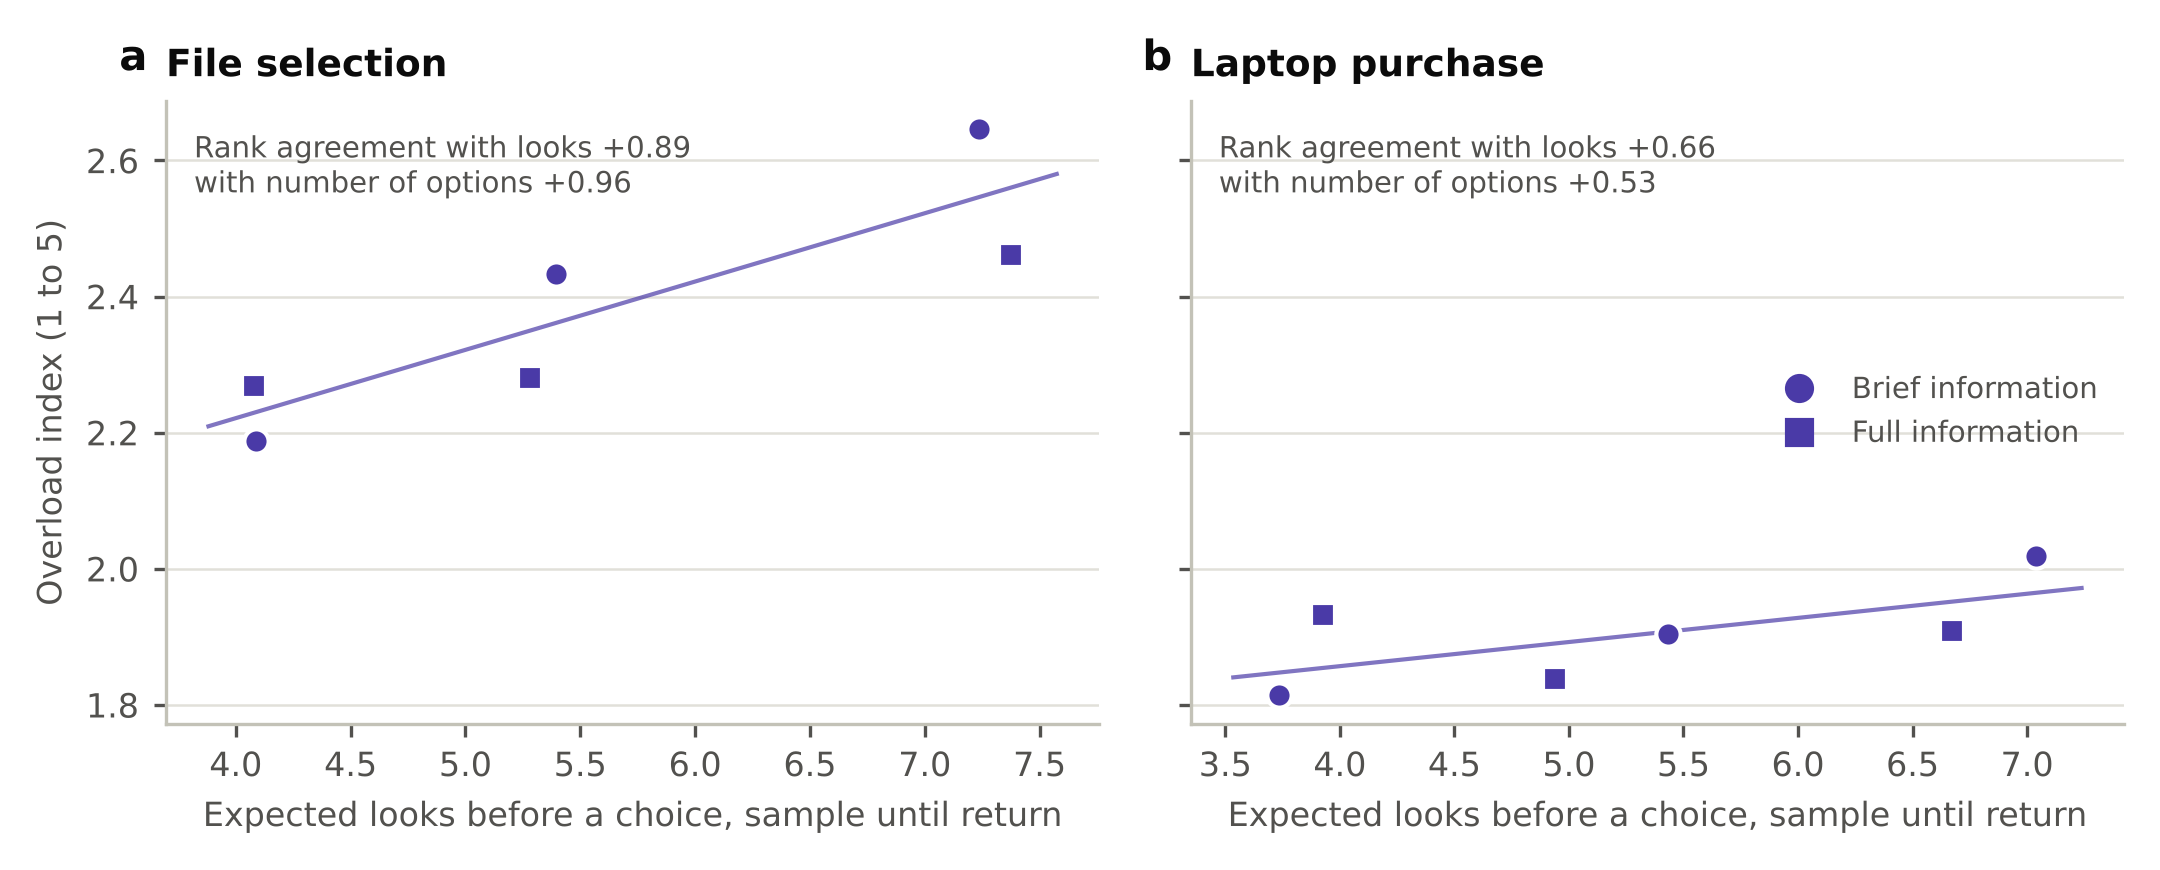

In [6]:
from overload.figures import figure_premonition
display(Markdown(section(tables, "## 3. Premonition, files")))
figure_premonition(proc, out / "fig_premonition")
display(Image(filename=str(out / "fig_premonition.png"), width=900))

**Findings.**

1. Within the file task, overload could be foreseen from the display. The number of options ordered the six file displays almost perfectly (rank correlation 0.96), and so did the models' forecasts of how spread the choices would be (0.89 to 0.94) and the search model's expected number of looks (0.89). Only MLBA's forecast beat a constant in held out error, by 0.064 scale points [0.003, 0.119].
2. Within the laptop task there was little to foresee, since overload stayed below average on every display.
3. No forecast foresaw the gap between the tasks. File and laptop displays of the same size drew similar forecasts but very different overload, so over all twelve displays no model forecast did better than a constant.
4. No model foresaw which displays would end in poor choices. Each model's expected regret predicted people's mean regret no better than a constant (an error of about 6 regret points). For laptops the search model came closest (4.9 against 5.7 points, not clear).

**Message.** Within a task, overload can be foreseen from the display, and the search model foresees it as well as counting options does. What made every file display overloading, not knowing what a file is worth, is in no model's forecast yet. With twelve displays this is as far as the development data go. The confirmatory tests move to open data with thousands of displays, where forecasts can be tested display by display.

## 5. Verification

**How.** Every result above was computed twice by the package, and the second run reproduced every saved value. An independent implementation, written blind from `verification/VERIFY_BRIEF_PROCESS.md` without access to the package, recomputed every value, and `verification/compare_process.py` compares the two value by value. The independent code is archived in `verification/independent_process`, and `sh verification/run_independent_process.sh PATH_TO_CSV` reruns it from scratch (about ten minutes).

In [7]:
indep = INDEPENDENT if INDEPENDENT.is_file() else REPO / "verification" / "independent_process" / "results.json"
r = subprocess.run([sys.executable, "verification/compare_process.py", "--independent", str(indep),
                    "--overload", "results/overload", "--process", "results/process_dev"],
                   cwd=REPO, capture_output=True, text=True)
print(r.stdout[-2600:] or r.stderr[-2600:])

Independent reimplementation against the package, overload, time, search models and premonition

Kind            checked   largest difference
association           9   0
clear               364   0
completeness         22   6.14e-07
completeness interval      88   1.67e-06
contrast             12   0
difference           20   6.14e-07
difference interval      80   1.58e-06
effort               96   6.21e-07
forecast            504   7.81e-07
forecast error      126   3.27e-09
forecast error interval     168   8.19e-09
forecast error p      42   0.002
interval           1008   6.85e-07
measurement           8   8.88e-16
outcome              48   0
p value             222   0
parameter           132   2.84e-07
per step             96   8.98e-08
regret error         63   3.29e-07
regret error interval      84   5.49e-07
regret error p       21   0
seconds              12   0
spearman             63   0
spearman interval     252   0.00682
spearman p           63   0.014
time error         

**Findings.**

1. The second run reproduced every saved value, including all 1000 resamples.
2. The independent implementation agreed on every value. Point values agreed to within 1e-6, and the fitted sensitivities of the search models to within 3e-7. In some resamples two forecasts that are equal up to 1e-7 were ranked differently by the two implementations, which moved a rank correlation bound by one step and a p value by a few resamples. No decision changed.
3. The verifier raised three points that shape the reading above. Combining both tasks mixes the gap between tasks into every forecast. Percentile intervals sit badly for rank correlations over six displays. Two file displays include timeouts at the 30 minute limit, 1.1 percent of the answers on each, recorded with the largest regret, and leaving them out changes no result.

## 6. What the development data say, and what comes next

- **Overload is display specific.** The same people were overloaded by large file displays and not by large laptop displays.
- **A model that searches matches the best choice accuracy.** Choices alone cannot tell processes apart, so the search model must prove itself on search, time and overload.
- **No model's work explains decision time on these displays.** Fitted to people's times, no time law did better than a forecast that ignores the display.
- **Premonition works within a task but not yet across tasks.** Twelve displays are too few to go further.

The confirmatory step tests the search model's predictions on open data it has never seen, frozen in advance by an amendment to the plan. The snack data of Thomas, Molter and Krajbich (2021) have thousands of random displays with response times and eye movements, so they test how search grows with the number of options, how long decisions take, and which displays will be slow or end in a poor choice, display by display.

## 7. The confirmatory test on the snack data (plan Amendment 5)

**Question.** Does the search model predict how people search, how long they take and what they choose, in data it has never seen?

**Why it matters.** The development data have only twelve displays, enough to build the model but not to test it. The snack data of Thomas, Molter and Krajbich (2021) have thousands of random displays of 9 to 36 snacks, each rated beforehand by the person choosing, with response times and eye movements. Their choices were used for H1, but their times and eye movements had never met a model.

**How.** Five tests were frozen in Amendment 5 before anything was run, and the analysis was run once. Every prediction comes from fits to the other three set sizes.
- **S1, search.** How the number of snacks looked at grows with set size, as an elasticity (1 means looking at every snack). Supported when people's growth is clearly below 1 and the model's predicted growth lies within 0.1 of it.
- **S2, time.** A time law, start up time plus time per step of the model's work, fitted on three set sizes and used to predict the response times of the fourth. Supported when the model's error is clearly below CL's and DbS's.
- **S3, slow decisions.** Within each person and set size, whether the trials the model expects to need more looks are the slow ones (rank correlation).
- **S4, missing the best.** How well each model foresees whether the chosen snack is the best rated one.
- **S5, choices.** Whether the model predicts the chosen snack at least as well as CL, the best static model on these data, to within 2 percent of the likelihood. Added at the author's request before the run. A design check (`scripts/simulate_choice_advantage.py`) showed that even if the search model were true, CL would trail it by less than 0.1 percent, so a tie is the expected outcome.

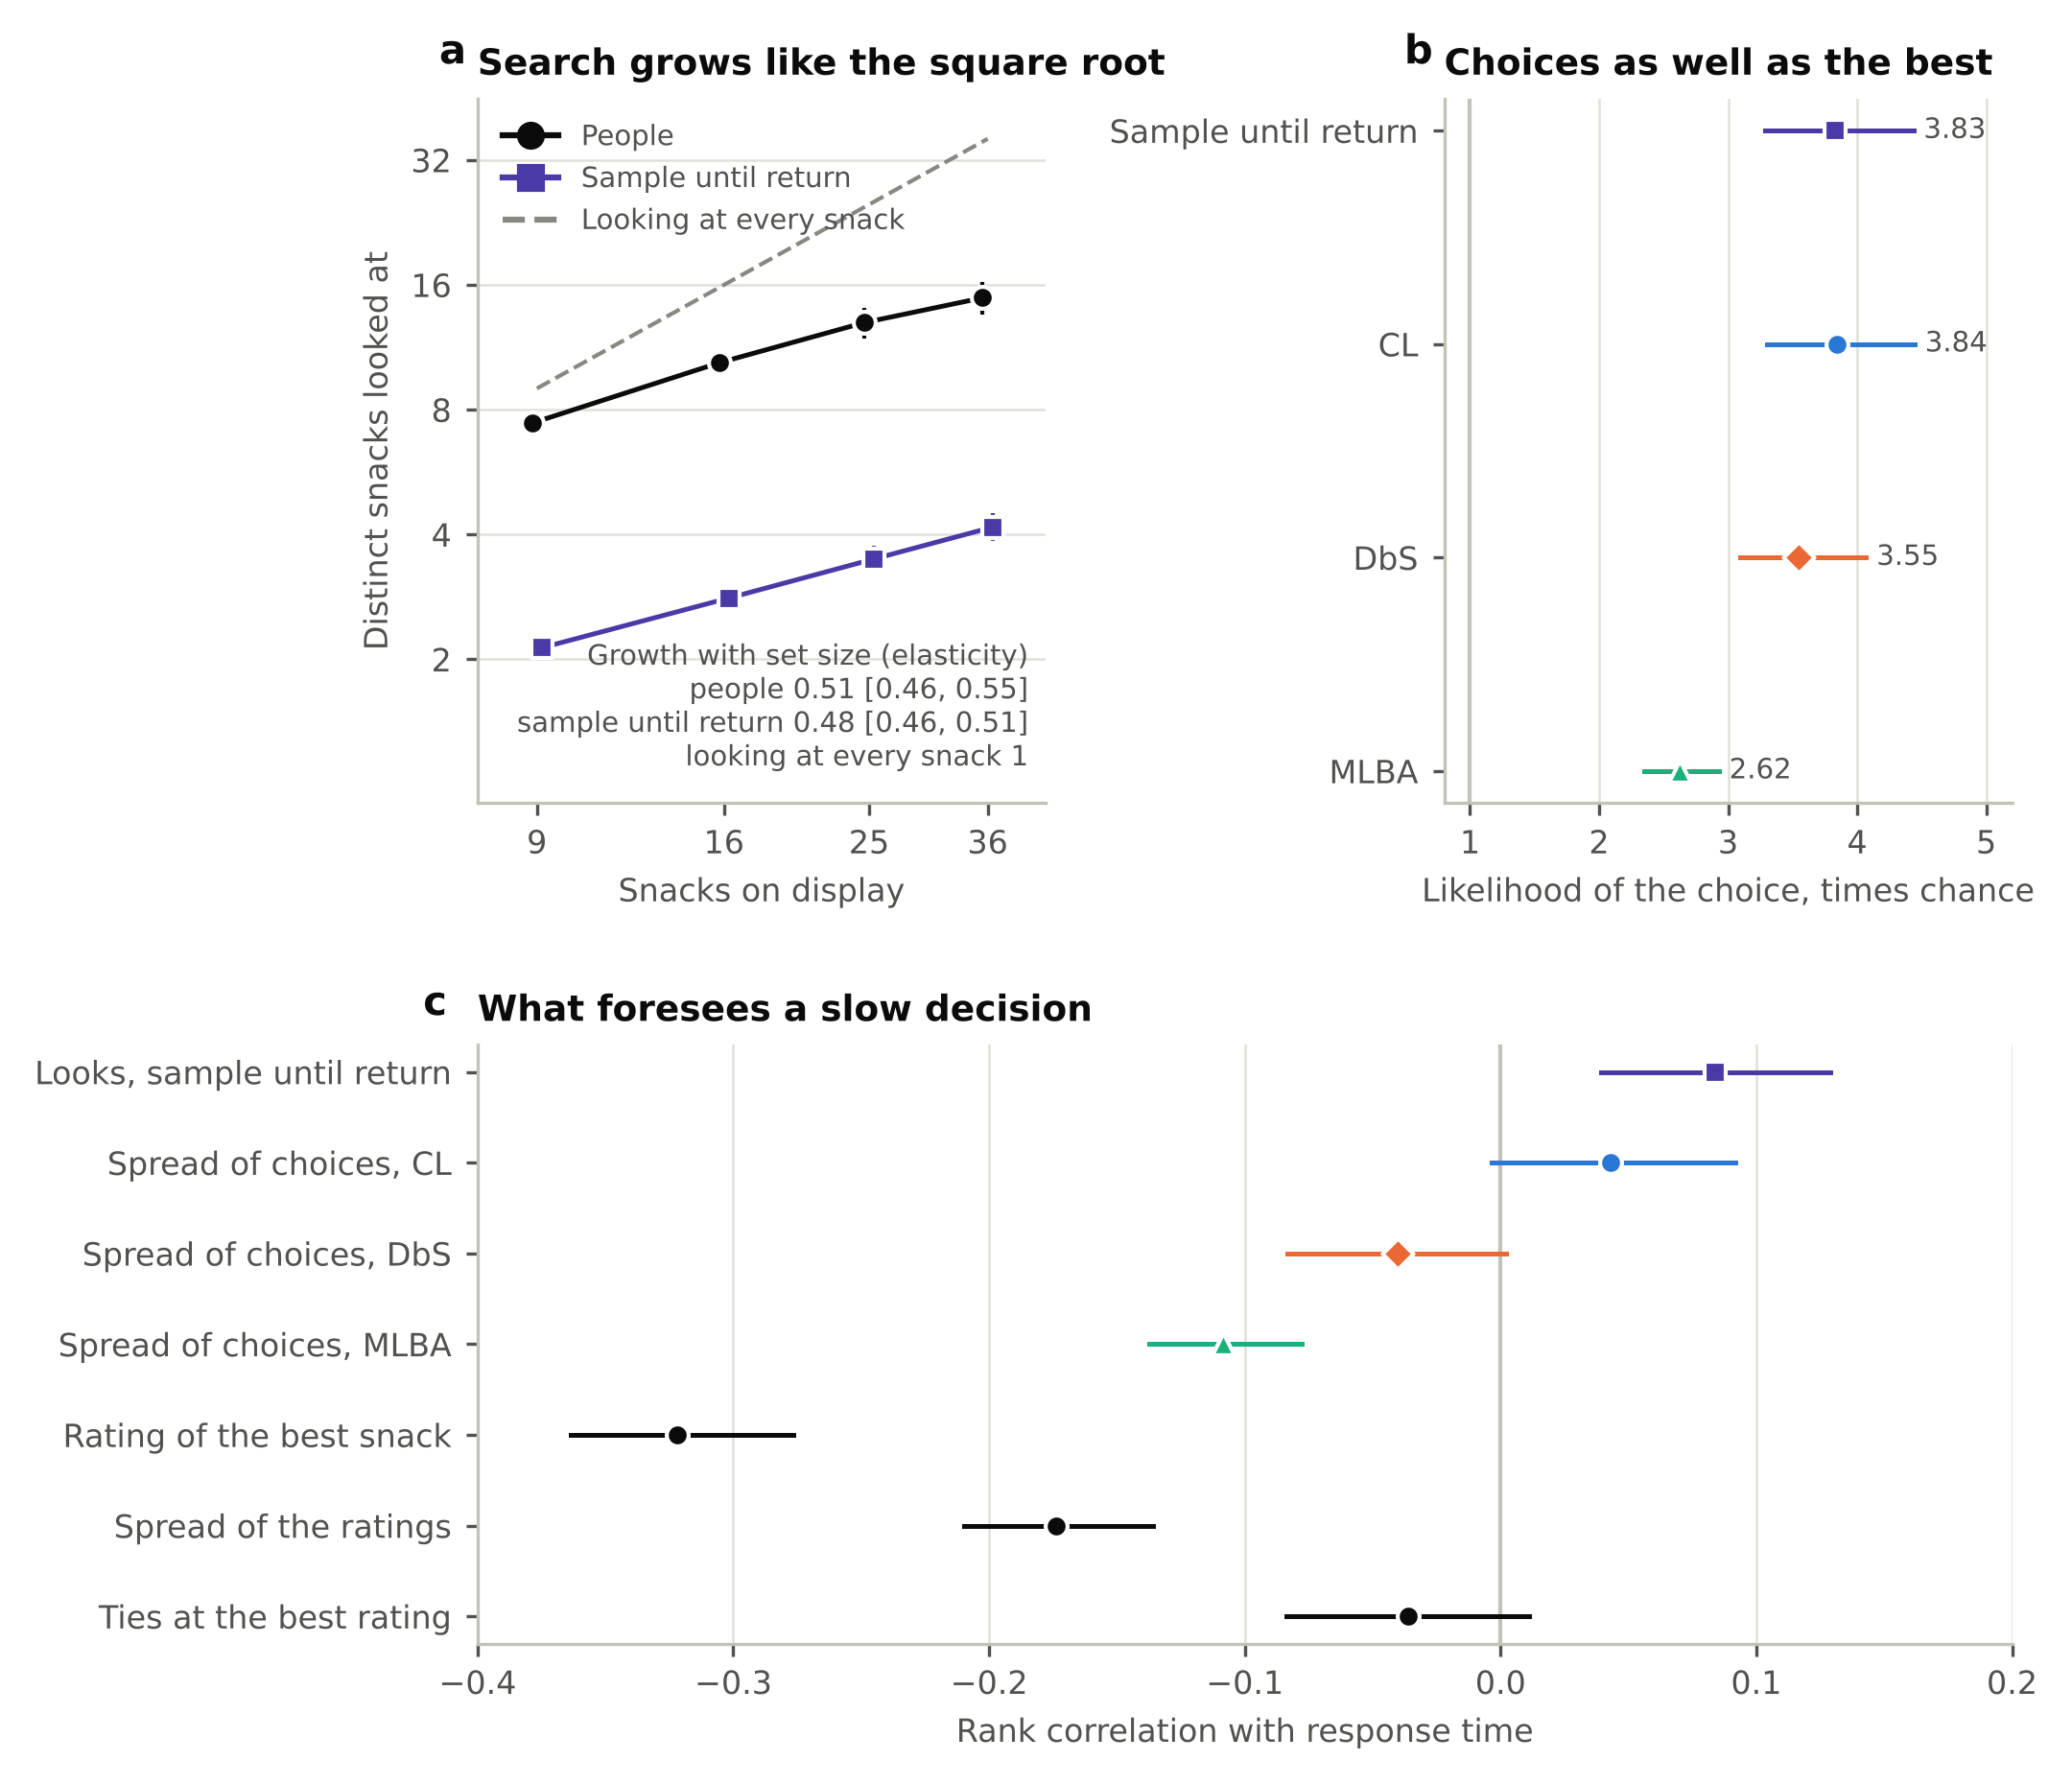

# Search model, confirmatory tests on the snack data (Amendment 5)

## S1, search grows sublinearly

| | 9 | 16 | 25 | 36 | Elasticity |
|---|---|---|---|---|---|
| Distinct items looked at, observed | 7.42 | 10.38 | 12.97 | 14.89 | 0.51 [0.46, 0.55] * |
| Predicted by sample until return | 2.13 | 2.81 | 3.49 | 4.17 | 0.48 [0.46, 0.51] * |
| Predicted by evaluating every item | 9 | 16 | 25 | 36 | 1 |
| Observed over predicted by sample until return | 3.48 | 3.69 | 3.72 | 3.57 | |

- Observed elasticity below one by 0.49 [0.45, 0.54] *.
- Predicted minus observed elasticity -0.02 [-0.07, 0.03], within the margin of 0.1 True. Supported True.

## S2, time held out (mean absolute error of log response time)

| Model | Error | 9 | 16 | 25 | 36 | Sample until return minus model |
|---|---|---|---|---|---|---|
| CL | 0.543 [0.498, 0.586] * | 0.485 | 0.523 | 0.576 | 0.589 | +0.009 [-0.003, 0.021] |
| DbS_avg | 0.550 [0.506, 0.592] * | 0.495 | 0.529 | 0.582 | 0.594 | +0.002 [-0.010, 0.015] |
| MLBA_avg | 0.550 [0.506, 0.592] * | 0.495 | 0.529 | 0.582 | 0.594 | +0.002 [-0.010, 0.015] |
| SR | 0.552 [0.504, 0.596] * | 0.500 | 0.521 | 0.582 | 0.607 |  |

Supported False.

## S3, premonition of slow decisions

| Forecast | Mean within participant rank correlation with response time |
|---|---|
| looks_SR | +0.084 [0.039, 0.129] * |
| entropy_CL | +0.043 [-0.004, 0.092] |
| entropy_DbS_avg | -0.040 [-0.083, 0.002] |
| entropy_MLBA_avg | -0.108 [-0.137, -0.078] * |
| top_rating | -0.322 [-0.364, -0.276] * |
| rating_sd | -0.174 [-0.210, -0.136] * |
| top_count | -0.036 [-0.084, 0.011] |

- Sample until return minus CL entropy +0.041 [0.030, 0.053] *. Supported True.

## S4, premonition of missing the best (bits per trial)

| Model | Log score | Minus constant |
|---|---|---|
| CL | -0.6651 [-0.7447, -0.5799] * | +0.0411 [0.0166, 0.0644] * |
| DbS_avg | -0.7704 [-0.8477, -0.6832] * | -0.0642 [-0.1060, -0.0227] * |
| MLBA_avg | -1.1472 [-1.2958, -1.0012] * | -0.4411 [-0.5842, -0.2936] * |
| SR | -0.6640 [-0.7445, -0.5771] * | +0.0422 [0.0169, 0.0663] * |
| constant | -0.7062 [-0.7799, -0.6235] * |  |

- Sample until return minus CL +0.0011 [-0.0017, 0.0037].

## S5, choices, held out likelihood of the chosen item relative to chance

- Sample until return minus CL -0.3 [-0.7, 0.0] percent (basic -0.7 to 0.0). Non inferior within 2 percent True, better False, worse False. Supported True.

## Secondary

Choices of every model, held out likelihood of the chosen item relative to chance.

| Model | Times chance | 9 | 16 | 25 | 36 | Sample until return minus model, % |
|---|---|---|---|---|---|---|
| CL | 3.84 [3.30, 4.45] | 2.86 | 3.64 | 4.37 | 4.80 | -0.3 [-0.7, 0.0] |
| DbS_avg | 3.55 [3.09, 4.07] | 2.64 | 3.48 | 4.03 | 4.28 | +8.0 [5.1, 11.0] * |
| MLBA_avg | 2.62 [2.35, 2.93] | 2.06 | 2.62 | 2.91 | 3.02 | +46.1 [30.6, 64.2] * |
| SR | 3.83 [3.29, 4.44] | 2.85 | 3.63 | 4.35 | 4.80 |  |

- Elasticity of CL's sensitivity implied by sample until return -0.010 [-0.032, 0.014] (observed in Amendment 3, +0.18).

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero.


In [8]:
from overload.experiments import search_confirmatory
from overload.figures import figure_search_confirmatory
snack_dir = REPO / "data" / "snack"
if not (snack_dir / "setsize-36_desc-data.csv").exists():
    subprocess.run(["sh", "scripts/fetch_snack_data.sh", str(snack_dir)], cwd=REPO, check=True)
out = REPO / "results" / "search_confirmatory"
if RECOMPUTE or not (out / "summary.json").exists():
    search_confirmatory.run(snack_dir, out, replicates=1000, jobs=JOBS)  # about 15 minutes with two processes
conf = json.loads((out / "summary.json").read_text())
figure_search_confirmatory(conf, out / "fig_search_confirmatory")
display(Image(filename=str(out / "fig_search_confirmatory.png"), width=900))
display(Markdown((out / "table_search_confirmatory.md").read_text()))

**Findings.**

1. **Search grew like the square root of the number of options, as the model predicted.** People looked at 7.4 snacks when 9 were shown and 14.9 when 36 were shown, an elasticity of 0.51 [0.46, 0.55]. The model predicted 0.48 [0.46, 0.51], well inside the margin, so S1 was supported. A process that evaluates every item predicts 1.
2. **The model's searches were too short.** At every set size people looked at about 3.6 times as many snacks as the model. The growth is right and the level is not. Either people do not stop at the first return to an option, or their attention is less drawn to value than their choices are.
3. **Single decisions were not timed better.** Held out, the time law built on the model's looks predicted log response times no better than one built on the number of options (error 0.552 against CL's 0.543, difference +0.009 [-0.003, 0.021]), so S2 was not supported.
4. **The model foresaw which decisions would be slow, though weakly.** Within a person and set size, its expected looks correlated +0.084 [0.039, 0.129] with response time, about twice CL's spread of choices (difference +0.041 [0.030, 0.053]), so S3 was supported. The strongest sign of a slow decision was something else. When the best snack on display was rated lower, people took longer (-0.32 [-0.36, -0.28]). The model reads only differences in value, so it cannot produce this.
5. **Choices were predicted as well as by the best model.** The chosen snack was 3.83 times as likely as chance under the model and 3.84 under CL, a difference of -0.3 percent [-0.7, 0.0], inside the 2 percent margin, so S5 was supported. The model beat DbS by 8.0 percent [5.1, 11.0] and MLBA by 46.1 percent [30.6, 64.2].
6. **Misses of the best snack were foreseen equally by the model and CL** (S4), both 0.04 bits per trial better than a constant forecast. DbS and MLBA did worse than the constant.

**Message.** People choose by a search whose length grows like the square root of what is on offer. A one parameter model of that search predicts choices as well as the best static model and is the only one that predicts how search grows. Neither it nor any other model times single decisions. What it lacks is an absolute standard. People stop sooner when something on display is really good, which points to the next version of the model and to a candidate for when choosing feels overwhelming, namely when nothing on display is good enough.

**Verification.** The analysis was run twice by the package, with identical results, and an independent implementation, written blind from `verification/VERIFY_BRIEF_SEARCH.md` and tested on simulated data before the real data were opened, recomputed every value. `verification/compare_search_confirmatory.py` compares them value by value, and `sh verification/run_independent_search.sh` reruns the independent code from scratch (about 20 minutes).

In [9]:
r = subprocess.run([sys.executable, "verification/compare_search_confirmatory.py",
                    "--independent", "verification/independent_search/results.json",
                    "--results", "results/search_confirmatory"], cwd=REPO, capture_output=True, text=True)
print(r.stdout[-1600:] or r.stderr[-1600:])

Independent reimplementation against the package, search model on the snack data (Amendment 5)

Kind            checked   largest difference
choices              24   9.07e-09
clear                34   0
decision              8   0
interval            144   0.000412
p value              34   0.002
parameter            16   1.72e-08
premonition          10   2.19e-10
rank correlation       8   0.000174
search               16   3.13e-08
secondary            21   2.85e-08
time                 23   3.87e-09

Every value agrees within tolerance.



**Findings.** The two implementations agreed on every value and every decision. Outside the rank correlations the largest difference was 3e-7 (on the percent scale of S5), from locating the model's sensitivity to about 1e-8. Rank correlations differed by up to 4e-4, where two forecasts equal to within rounding were ranked in different orders. The verifier also reran the amendment's exact fitting procedure and found the same sensitivities to within 3e-8.

## 8. What the paper can now say

- **Overload is display specific.** The same people were overloaded by large file displays and not by large laptop displays (development data).
- **People search rather than weigh everything.** On the snack data, the number of options people looked at grew like the square root of what was on offer, as the search model predicted before it saw these data. Weighing every option would make it grow in proportion.
- **Choices cannot reveal the process.** Given the same values, searching and weighing predict the same choices, in theory (the design check), on the development data and on the snack data. Process models therefore have to be judged on how people search, and there the search model's prediction matched people.
- **No model's work explains how long people take.** On the development displays no time law beat a forecast that ignores the display, and on the snack data none timed single decisions better than counting the options.
- **The search model is as accurate as the best model and predicts how search grows, but it is not yet complete.** It stops too early and ignores how good the best option is in absolute terms.

**Next.** A search that stops at an option that is good enough in absolute terms would lengthen searches, speed decisions on displays with a clearly good option, and say when overload should arise. It was suggested by the snack data, so it must be tested on data it has not seen. Section 9 builds it and explores it on the snack data, section 10 tests it on three gaze datasets it had never seen, section 11 asks whether worse choices mean felt overload, section 12 tests the stopping rule where values must be worked out, section 13 tests whether the models forecast choice overload, and section 14 sums up. Candidates are the gaze data of Thomas, Molter, Krajbich, Heekeren and Mohr (2019) and the search and satisficing data of Caplin, Dean and Martin (2011), whose values are money.

## 9. Exploratory. A search model with an absolute standard

**Question.** Can the search model learn what makes a decision fast, an option that is good in absolute terms, without a new free parameter?

**Why it matters.** In the confirmatory test the strongest sign of a slow decision was a display without a really good snack. Sample until return cannot see this, because it compares options only with each other.

**How.** *Two look satisficing* keeps the search and adds a standard.
- Attention is drawn to attractive options, as before.
- A look registers, meaning the option looks good enough at that moment, with a probability that rises with its rating relative to the top of the rating scale, exp(lambda (v - v_top) / 2).
- The first option whose looks register twice is chosen.

Attention and registration take half the sensitivity each, so the model's choices are exactly those of sample until return and no parameter is added. Only time and search can differ. The model is compared with sample until return and CL on held out time, on foreseeing slow decisions and on search, on the same resamples as Amendment 5.

The snack data suggested this model, so everything here is exploratory, and its test must be frozen on data it has not seen.

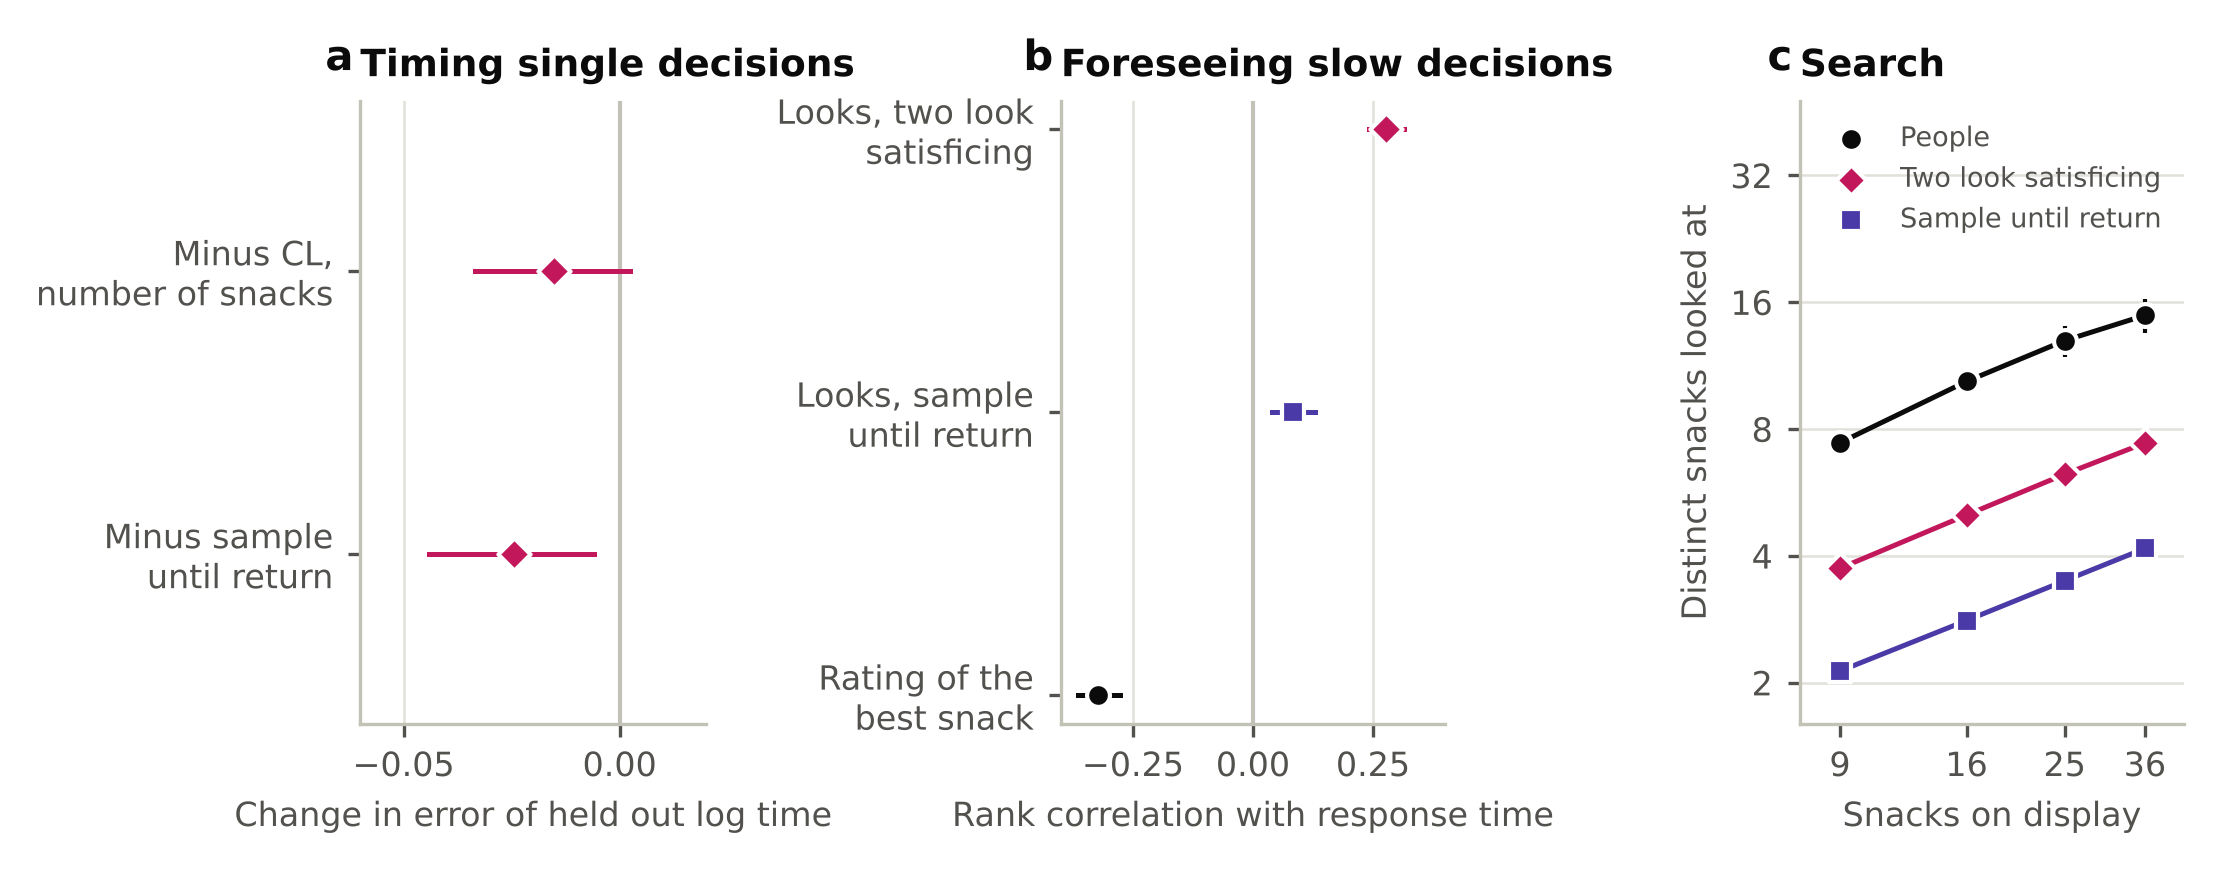

# Two look satisficing on the snack data (exploratory)

## E1, time held out (mean absolute error of log response time)

| Model | Error | 9 | 16 | 25 | 36 |
|---|---|---|---|---|---|
| CL | 0.543 [0.498, 0.586] * | 0.485 | 0.523 | 0.576 | 0.589 |
| SR | 0.552 [0.504, 0.596] * | 0.500 | 0.521 | 0.582 | 0.607 |
| TLS | 0.528 [0.484, 0.568] * | 0.460 | 0.497 | 0.562 | 0.593 |

- Two look satisficing minus CL -0.0153 [-0.0336, 0.0024], minus sample until return -0.0245 [-0.0441, -0.0058] *.

## E2, slow decisions (mean within participant rank correlation with response time)

| Forecast | Correlation |
|---|---|
| looks_TLS | +0.278 [0.241, 0.315] * |
| looks_SR | +0.084 [0.039, 0.129] * |
| top_rating | -0.322 [-0.364, -0.276] * |

- Two look satisficing minus sample until return +0.194 [0.156, 0.233] *. Two look satisficing plus best rating -0.044 [-0.072, -0.020] * (zero would mean the model carries all of the best rating's link with time).

## E3, distinct snacks looked at

| | 9 | 16 | 25 | 36 | Elasticity |
|---|---|---|---|---|---|
| People | 7.42 | 10.38 | 12.97 | 14.89 | 0.51 [0.46, 0.55] * |
| Two look satisficing | 3.74 | 5.00 | 6.25 | 7.41 | 0.50 [0.47, 0.51] * |
| Sample until return | 2.13 | 2.81 | 3.49 | 4.17 | |

- Predicted minus observed elasticity -0.01 [-0.06, 0.03]. People over model, 1.99, 2.08, 2.08, 2.01.

## Sensitivity, attention that ignores value (point estimates)

- Time error 0.543, rank correlation with time +0.303, distinct snacks 6.98, 10.66, 14.49, 18.20, elasticity 0.69.

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero. Exploratory, these data suggested the model.


In [10]:
from overload.experiments import two_look_snack
from overload.figures import figure_two_look
out = REPO / "results" / "two_look_snack"
if RECOMPUTE or not (out / "summary.json").exists():
    two_look_snack.run(snack_dir, out, replicates=1000, jobs=JOBS)  # about 12 minutes with two processes
tls = json.loads((out / "summary.json").read_text())
figure_two_look(tls, out / "fig_two_look")
display(Image(filename=str(out / "fig_two_look.png"), width=900))
display(Markdown((out / "table_two_look_snack.md").read_text()))

**Findings.**

1. **The standard lets the search foresee slow decisions.** Within a person and set size, the model's expected looks correlated +0.28 [0.24, 0.32] with response time, against +0.08 for sample until return (difference +0.19 [0.16, 0.23]). The rating of the best snack on display still did slightly better (-0.32, model plus it -0.04 [-0.07, -0.02]), so the model carries most but not all of that link.
2. **It timed single decisions better than sample until return** (held out error 0.528 against 0.552, difference -0.025 [-0.044, -0.006]), **but not clearly better than counting the snacks** (CL's law, 0.543, difference -0.015 [-0.034, 0.002]).
3. **Search kept its growth and came closer in level.** The model looked at 3.7 snacks at 9 and 7.4 at 36, about half of what people looked at, against a quarter for sample until return. Its growth was right (elasticity 0.50 against people's 0.51).
4. **Choices were unchanged**, as accurate as CL, by construction.
5. **A variant in which attention ignores value** matched the level of search at 9 and 16 snacks, but its search grew too fast (elasticity 0.69) and it timed decisions no better than CL.

**Message.** An absolute standard can be built into the search without a new parameter, and it explains most of why some decisions are slow. It is the candidate the next confirmatory test must check on data it has never seen.

**Verification.** Run twice by the package with identical results, and recomputed by an independent implementation written blind from `verification/VERIFY_BRIEF_TWO_LOOK.md` (`sh verification/run_independent_two_look.sh` reruns it, about 20 minutes).

In [11]:
r = subprocess.run([sys.executable, "verification/compare_two_look.py",
                    "--independent", "verification/independent_two_look/results.json",
                    "--results", "results/two_look_snack"], cwd=REPO, capture_output=True, text=True)
print(r.stdout[-1200:] or r.stderr[-1200:])

Independent reimplementation against the package, two look satisficing on the snack data

Kind            checked   largest difference
clear                13   0
interval             68   4.76e-05
p value              13   0
parameter             4   1.72e-08
rank correlation       5   2.18e-05
search               19   4.17e-08
sensitivity           7   6.21e-08
time                 41   3.42e-07

Every value agrees within tolerance.



**Findings.** The two implementations agreed on every value, with a largest difference of 3e-7 outside rank statistics and 5e-5 for them. Every quantity this analysis shares with Amendment 5 reproduces it exactly in both. The verifier noted that the model's gain in foreseeing slow decisions comes largely from the top of the rating scale, since displays without a top rated snack register looks slowly.

## 10. Confirmatory. Two look satisficing on three gaze datasets (Amendment 6)

**Question.** Does the absolute standard of section 9 hold on data it has never seen?

**Why it matters.** The snack data suggested two look satisficing, so its gains there could be a good fit rather than a real mechanism. A test frozen before new data are analyzed tells the two apart.

**How.** Three open datasets of choices between two or three foods, each rated beforehand by the person choosing. Krajbich, Armel and Rangel (2010) offered two foods, Krajbich and Rangel (2011) three foods and Folke and colleagues (2016) three snacks, as prepared by Thomas and colleagues (2019). Every display in a dataset has the same number of items, so a model that times decisions by the number of options predicts one time for every trial, while the search models predict from the values alone which trials take longer. Every prediction comes from fits to other people, in ten folds of participants. The tests were frozen in Amendment 6 before these data were analyzed, and run once.
- **G1, time.** Two look satisficing should time the single decisions of people held out better than sample until return and better than one constant time.
- **G2, slow decisions.** Within each person, its expected looks should rank slow decisions above fast ones better than sample until return's looks do.
- **G3, choices.** It should predict choices as well as CL, within 2 percent of the likelihood of the choice.


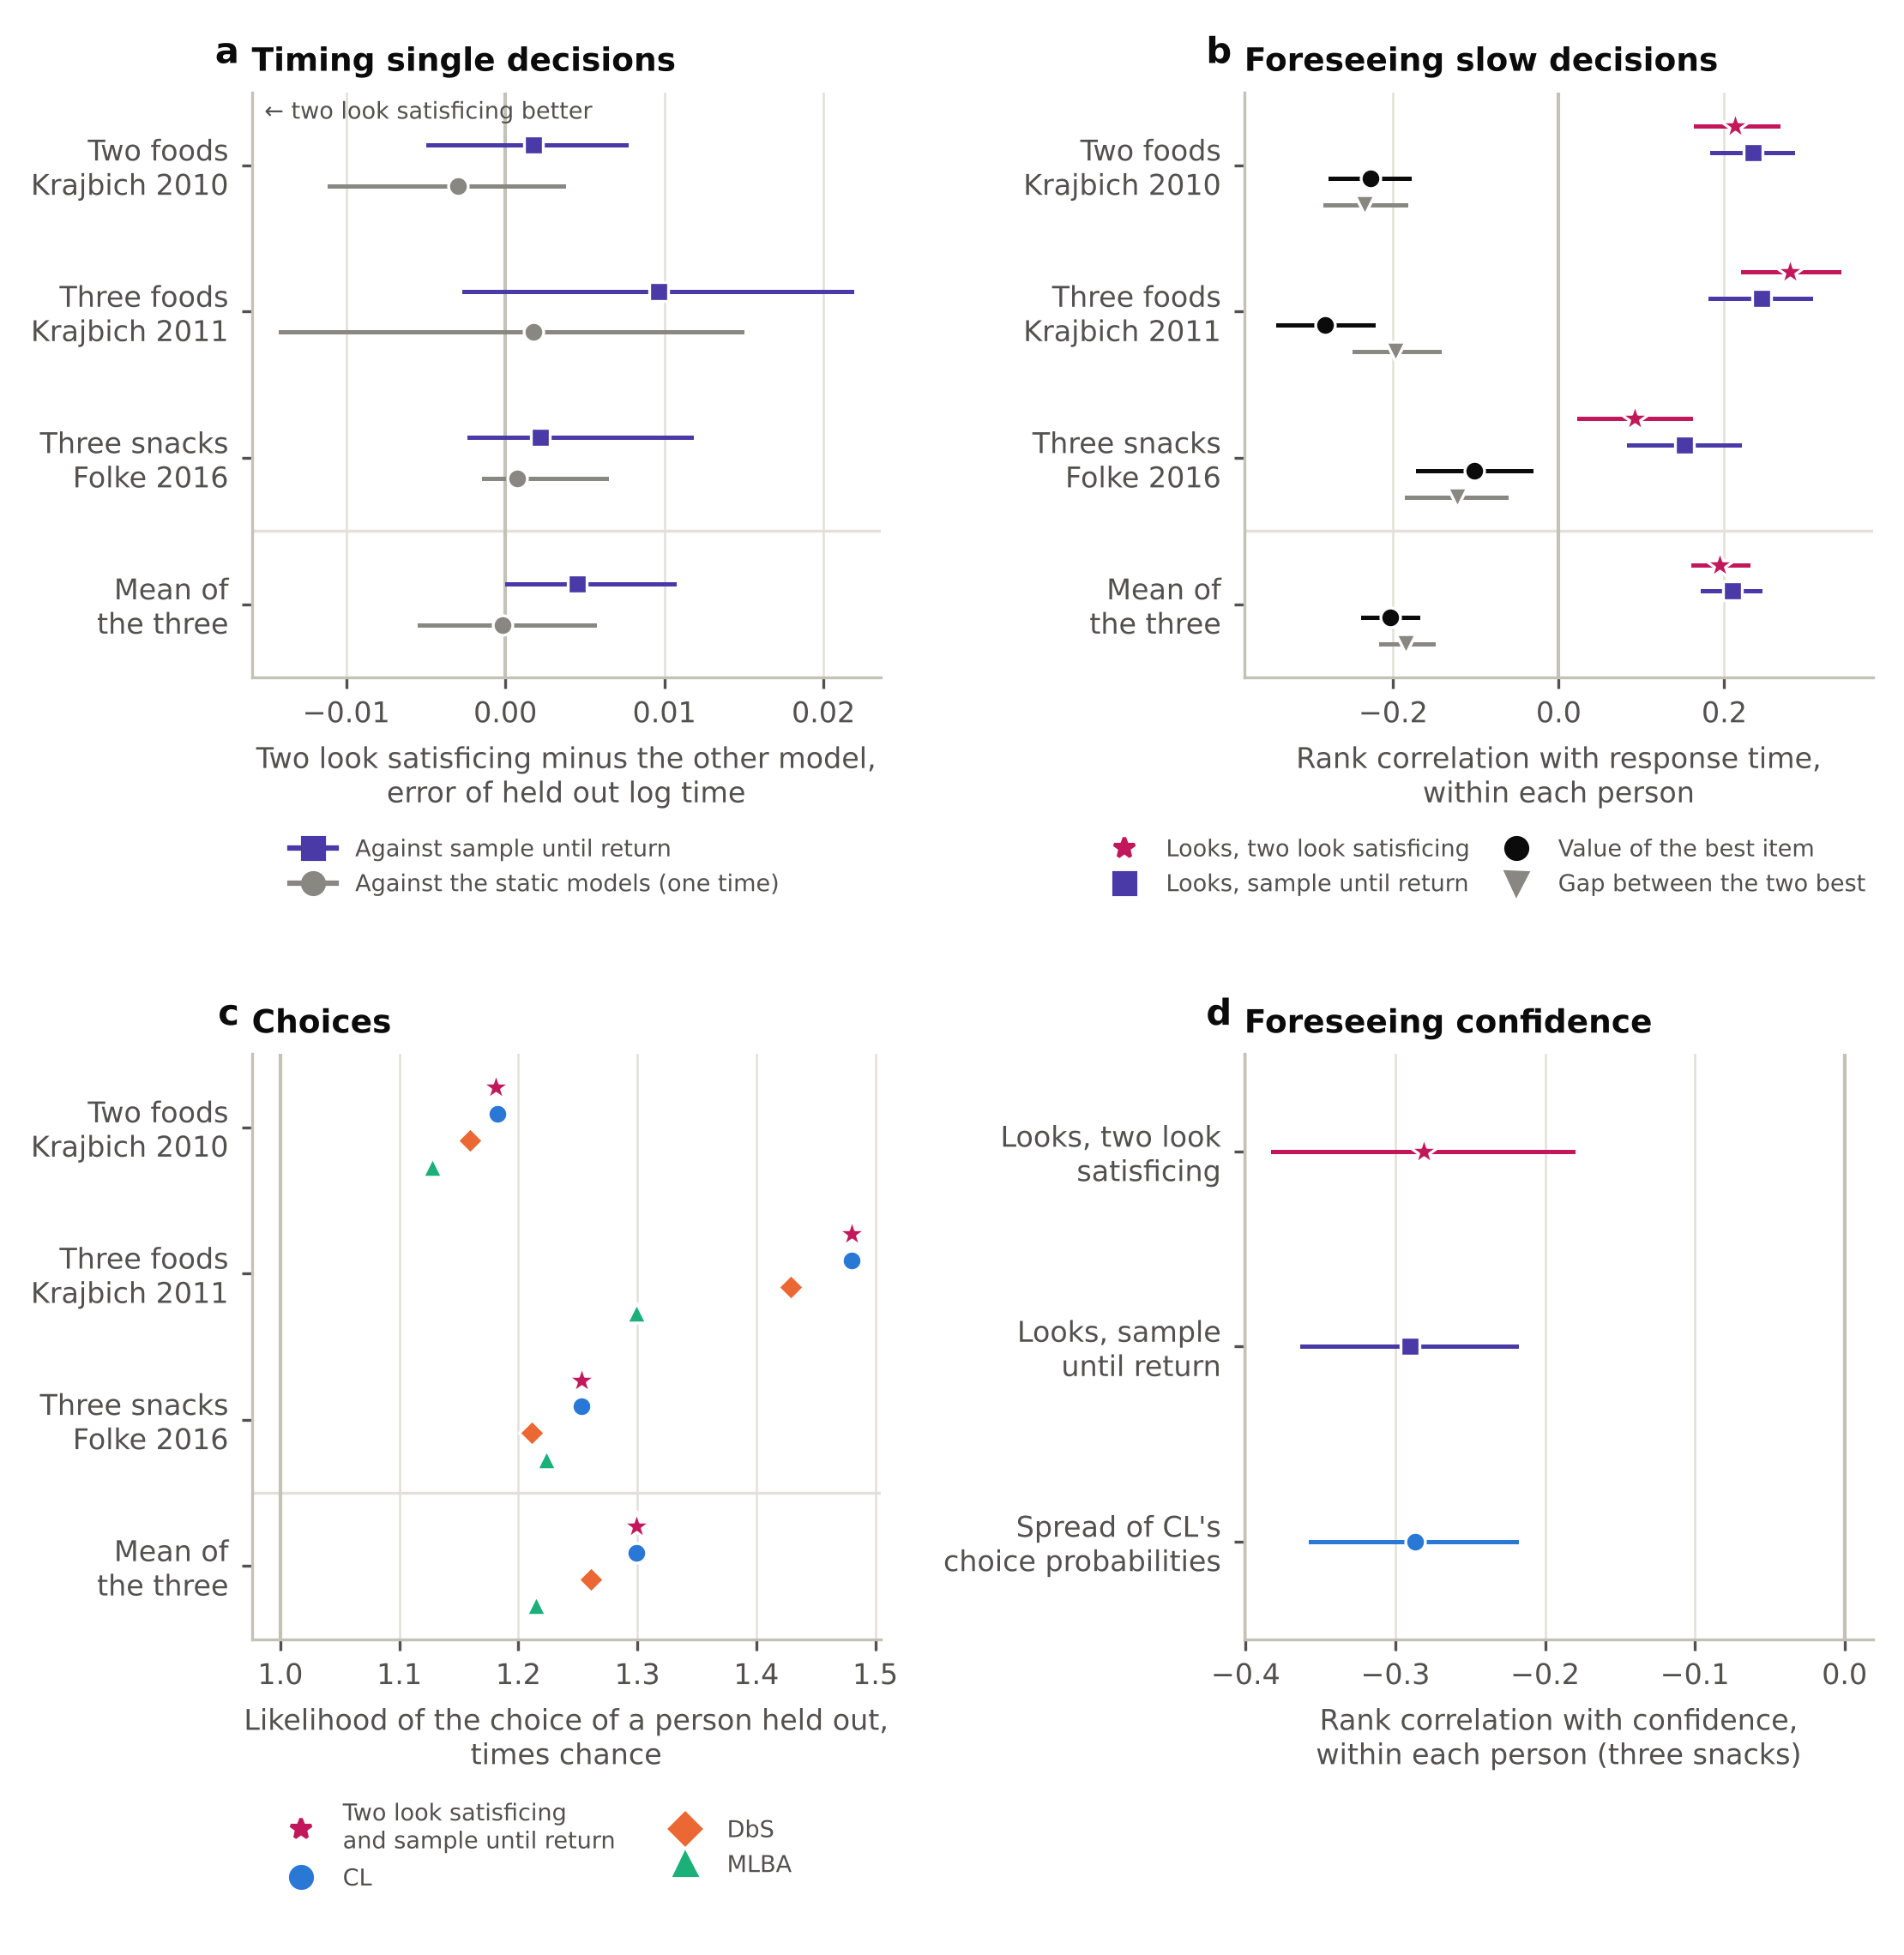

# Two look satisficing on three gaze datasets (Amendment 6, confirmatory)

## Decisions

- G1, time held out. Two look satisficing minus sample until return +0.0045 [0.0001, 0.0106], minus the static models -0.0002 [-0.0054, 0.0056]. Supported False.
- G2, slow decisions. Two look satisficing +0.194 [0.162, 0.229] *, minus sample until return -0.016 [-0.040, 0.011]. Supported False.
- G3, choices. Two look satisficing minus CL -0.0 [-0.1, 0.0] percent. Non inferior within 2 percent True, better False, worse False. Supported True.

## Pooled (mean of the three datasets)

| Measure | Value |
|---|---|
| Time error, static | 0.445 [0.413, 0.482] * |
| Time error, SR | 0.440 [0.409, 0.479] * |
| Time error, TLS | 0.445 [0.412, 0.486] * |
| Time error, TLS minus SR | +0.0045 [0.0001, 0.0106] |
| Time error, TLS minus static | -0.0002 [-0.0054, 0.0056] |
| Rank correlation with time, looks_TLS | +0.194 [0.162, 0.229] * |
| Rank correlation with time, looks_SR | +0.210 [0.174, 0.243] * |
| Rank correlation with time, top_value | -0.204 [-0.237, -0.170] * |
| Rank correlation with time, mean_value | -0.137 [-0.168, -0.107] * |
| Rank correlation with time, top_gap | -0.185 [-0.215, -0.152] * |
| Rank correlation with time, TLS minus SR | -0.016 [-0.040, 0.011] |
| Rank correlation with time, TLS plus top_value | -0.009 [-0.015, -0.003] * |
| Rank correlation with time, TLS plus mean_value | +0.057 [0.045, 0.073] * |
| Rank correlation with time, TLS plus top_gap | +0.010 [-0.017, 0.039] |
| Choices, times chance, CL, DbS, MLBA, SR | 1.299, 1.261, 1.215, 1.299 |
| Choices, TLS minus CL, percent | -0.04 [-0.15, 0.03] |
| Choices, TLS minus DbS, percent | +2.99 [1.24, 4.50] * |
| Choices, TLS minus MLBA, percent | +6.94 [4.96, 8.87] * |

## krajbich2010

| Measure | Value |
|---|---|
| Time error, static | 0.447 [0.396, 0.499] * |
| Time error, SR | 0.442 [0.391, 0.495] * |
| Time error, TLS | 0.444 [0.392, 0.498] * |
| Time error, TLS minus SR | +0.0018 [-0.0049, 0.0076] |
| Time error, TLS minus static | -0.0030 [-0.0111, 0.0036] |
| Rank correlation with time, looks_TLS | +0.213 [0.165, 0.265] * |
| Rank correlation with time, looks_SR | +0.235 [0.185, 0.282] * |
| Rank correlation with time, top_value | -0.227 [-0.276, -0.180] * |
| Rank correlation with time, mean_value | -0.164 [-0.219, -0.115] * |
| Rank correlation with time, top_gap | -0.235 [-0.282, -0.185] * |
| Rank correlation with time, TLS minus SR | -0.022 [-0.073, 0.041] |
| Rank correlation with time, TLS plus top_value | -0.014 [-0.021, -0.004] * |
| Rank correlation with time, TLS plus mean_value | +0.049 [0.036, 0.066] * |
| Rank correlation with time, TLS plus top_gap | -0.022 [-0.073, 0.041] |
| Choices, times chance, CL, DbS, MLBA, SR | 1.183, 1.159, 1.128, 1.181 |
| Choices, TLS minus CL, percent | -0.13 [-0.40, 0.01] |
| Choices, TLS minus DbS, percent | +1.92 [-0.74, 3.74] |
| Choices, TLS minus MLBA, percent | +4.76 [1.69, 7.09] * |
| Law fitted to everyone, SR, start up seconds and seconds per look | 0.000 [0.000, 0.000] *, 0.759 [0.681, 0.843] * |
| Expected looks, SR, held out mean | 2.42 [2.39, 2.43] * |
| Law fitted to everyone, TLS, start up seconds and seconds per look | 1.527 [1.267, 1.759] *, 0.042 [0.012, 0.085] |
| Expected looks, TLS, held out mean | 7.38 [5.96, 9.32] * |
| Typical response time, seconds (geometric mean) | 1.83 [1.65, 2.03] * |

## krajbich2011

| Measure | Value |
|---|---|
| Time error, static | 0.469 [0.397, 0.559] * |
| Time error, SR | 0.461 [0.387, 0.551] * |
| Time error, TLS | 0.471 [0.391, 0.567] * |
| Time error, TLS minus SR | +0.0096 [-0.0026, 0.0218] |
| Time error, TLS minus static | +0.0018 [-0.0141, 0.0148] |
| Rank correlation with time, looks_TLS | +0.279 [0.222, 0.339] * |
| Rank correlation with time, looks_SR | +0.245 [0.183, 0.304] * |
| Rank correlation with time, top_value | -0.282 [-0.339, -0.225] * |
| Rank correlation with time, mean_value | -0.207 [-0.257, -0.151] * |
| Rank correlation with time, top_gap | -0.197 [-0.247, -0.145] * |
| Rank correlation with time, TLS minus SR | +0.034 [0.001, 0.072] |
| Rank correlation with time, TLS plus top_value | -0.003 [-0.013, 0.007] |
| Rank correlation with time, TLS plus mean_value | +0.072 [0.044, 0.110] * |
| Rank correlation with time, TLS plus top_gap | +0.082 [0.031, 0.131] * |
| Choices, times chance, CL, DbS, MLBA, SR | 1.480, 1.429, 1.299, 1.480 |
| Choices, TLS minus CL, percent | +0.03 [-0.09, 0.12] |
| Choices, TLS minus DbS, percent | +3.62 [1.84, 5.13] * |
| Choices, TLS minus MLBA, percent | +13.97 [10.31, 17.60] * |
| Law fitted to everyone, SR, start up seconds and seconds per look | 0.000 [0.000, 0.000] *, 0.767 [0.673, 0.886] * |
| Expected looks, SR, held out mean | 2.65 [2.60, 2.69] * |
| Law fitted to everyone, TLS, start up seconds and seconds per look | 1.599 [1.133, 2.170] *, 0.065 [0.000, 0.151] |
| Expected looks, TLS, held out mean | 6.61 [5.79, 7.80] * |
| Typical response time, seconds (geometric mean) | 2.02 [1.76, 2.35] * |

## folke2016

| Measure | Value |
|---|---|
| Time error, static | 0.419 [0.392, 0.457] * |
| Time error, SR | 0.418 [0.391, 0.456] * |
| Time error, TLS | 0.420 [0.392, 0.459] * |
| Time error, TLS minus SR | +0.0022 [-0.0023, 0.0117] |
| Time error, TLS minus static | +0.0007 [-0.0013, 0.0064] |
| Rank correlation with time, looks_TLS | +0.091 [0.025, 0.159] * |
| Rank correlation with time, looks_SR | +0.151 [0.084, 0.218] * |
| Rank correlation with time, top_value | -0.102 [-0.170, -0.033] * |
| Rank correlation with time, mean_value | -0.040 [-0.101, 0.021] |
| Rank correlation with time, top_gap | -0.123 [-0.183, -0.063] * |
| Rank correlation with time, TLS minus SR | -0.060 [-0.103, -0.023] * |
| Rank correlation with time, TLS plus top_value | -0.011 [-0.022, 0.001] |
| Rank correlation with time, TLS plus mean_value | +0.051 [0.032, 0.072] * |
| Rank correlation with time, TLS plus top_gap | -0.032 [-0.073, 0.008] |
| Choices, times chance, CL, DbS, MLBA, SR | 1.253, 1.212, 1.224, 1.253 |
| Choices, TLS minus CL, percent | -0.01 [-0.17, 0.09] |
| Choices, TLS minus DbS, percent | +3.44 [-0.48, 7.23] |
| Choices, TLS minus MLBA, percent | +2.42 [-1.35, 6.66] |
| Law fitted to everyone, SR, start up seconds and seconds per look | 0.534 [0.000, 4.749], 1.530 [0.000, 1.876] |
| Expected looks, SR, held out mean | 2.75 [2.69, 2.79] * |
| Law fitted to everyone, TLS, start up seconds and seconds per look | 4.719 [3.884, 5.152] *, 0.001 [0.000, 0.056] |
| Expected looks, TLS, held out mean | 12.02 [8.25, 19.71] * |
| Typical response time, seconds (geometric mean) | 4.74 [4.31, 5.23] * |

## Folke 2016, confidence (rank correlation within participant)

| Forecast | Correlation |
|---|---|
| looks_TLS | -0.281 [-0.382, -0.181] * |
| looks_SR | -0.290 [-0.362, -0.219] * |
| entropy_CL | -0.287 [-0.357, -0.219] * |
| TLS_minus_SR | +0.009 [-0.040, 0.066] |

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero.


In [12]:
from overload.experiments import two_look_gaze
from overload.figures import figure_two_look_gaze
gaze_dir = REPO / "data" / "gaze"
out = REPO / "results" / "two_look_gaze"
if RECOMPUTE or not (out / "summary.json").exists():
    if not (gaze_dir / "folke2016_original.csv").exists():
        subprocess.run(["sh", "scripts/fetch_gaze_data.sh", str(gaze_dir)], cwd=REPO, check=True)
    two_look_gaze.run(gaze_dir, out, replicates=1000, jobs=JOBS)  # about 15 minutes with two processes
gz = json.loads((out / "summary.json").read_text())
figure_two_look_gaze(gz, out / "fig_two_look_gaze")
display(Image(filename=str(out / "fig_two_look_gaze.png"), width=900))
display(Markdown((out / "table_two_look_gaze.md").read_text()))


**Findings.**

1. **The absolute standard did not carry over (G1 and G2 not supported).** Two look satisficing timed single decisions no better than one constant time (difference in error -0.0002 [-0.0054, 0.0056]) and slightly worse than sample until return (+0.0045 [0.0001, 0.0106], not clear). Within each person its looks foresaw slow decisions (+0.19 [0.16, 0.23]), but sample until return's looks did so just as well (+0.21 [0.17, 0.24], difference -0.016 [-0.040, 0.011]). In Folke's snacks sample until return was clearly better, and in Krajbich's three foods two look satisficing leaned the other way without being clear.
2. **Choices were as accurate as CL (G3 supported)**, -0.04 percent [-0.15, 0.03], and better than DbS (+3.0 percent [1.2, 4.5]) and MLBA (+6.9 percent [5.0, 8.9]).
3. **A display's best item told as much as either model.** The value of the best item foresaw slow decisions about as well (-0.20), and slightly better than two look satisficing's looks (sum -0.009, clear).
4. **Confidence.** In Folke's data, more expected looks went with lower confidence for both models (-0.28 and -0.29), as did a wider spread of CL's choice probabilities (-0.29). No forecast stood out.

**Message.** The absolute standard was a feature of the snack data, not of how people decide in general. The plain search model is what held up. Sample until return chose as well as CL and, over the three datasets taken together, better than DbS and MLBA, and its looks told which decisions would be slow in every dataset.


**Exploratory.** How well does the search model that held up, sample until return, time decisions on these new data? These comparisons were not among the frozen tests and are computed from the same resamples.


In [13]:
from overload.bootstrap import summarize
reps = [json.loads(line) for line in (out / "replicates.jsonl").open()]
point = json.loads((out / "point.json").read_text())
sets = ("krajbich2010", "krajbich2011", "folke2016")


def interval(get, digits=4):
    e = summarize(get(point), [get(r) for r in reps])
    star = " *" if e["clear"] else ""
    return f"{e['point']:+.{digits}f} [{e['percentile'][0]:+.{digits}f}, {e['percentile'][1]:+.{digits}f}]{star}"


def row(label, get_pooled, get_set, digits=4):
    cells = [interval(get_pooled, digits)] + [interval(lambda r, s=s: get_set(r["datasets"][s]), digits) for s in sets]
    return f"| {label} | " + " | ".join(cells) + " |"


rows = ["| | Mean of the three | " + " | ".join(sets) + " |", "|---|---|---|---|---|"]
rows.append(row("Time error, SR minus one constant time",
                lambda r: r["pooled"]["time"]["SR"] - r["pooled"]["time"]["static"],
                lambda D: D["time"]["SR"] - D["time"]["static"]))
for f, label in (("top_value", "the value of the best item"), ("top_gap", "the gap between the two best")):
    rows.append(row(f"Slow decisions, SR's looks plus {label}",
                    lambda r, f=f: r["pooled"]["slow"]["looks_SR"] + r["pooled"]["slow"][f],
                    lambda D, f=f: D["slow"]["looks_SR"] + D["slow"][f], 3))
display(Markdown("\n".join(rows)))


def two(e):
    return f"{e['point']:.2f} [{e['percentile'][0]:.2f}, {e['percentile'][1]:.2f}]"


law = ["| | Start up, seconds | Seconds per look | Expected looks | Typical seconds |", "|---|---|---|---|---|"]
for s in sets:
    L = gz[s]["law"]["SR"]
    law.append(f"| {s} | {two(L['t0'])} | {two(L['tau'])} | {two(gz[s]['looks']['SR'])} | {two(gz[s]['typical_seconds'])} |")
display(Markdown("Sample until return's time law, fitted to everyone\n\n" + "\n".join(law)))


| | Mean of the three | krajbich2010 | krajbich2011 | folke2016 |
|---|---|---|---|---|
| Time error, SR minus one constant time | -0.0047 [-0.0080, -0.0021] * | -0.0048 [-0.0074, -0.0018] * | -0.0078 [-0.0131, -0.0032] * | -0.0014 [-0.0091, +0.0034] |
| Slow decisions, SR's looks plus the value of the best item | +0.007 [-0.017, +0.030] | +0.008 [-0.050, +0.058] | -0.038 [-0.072, -0.006] * | +0.049 [+0.018, +0.090] * |
| Slow decisions, SR's looks plus the gap between the two best | +0.025 [+0.015, +0.036] * | +0.000 [+0.000, +0.000] | +0.048 [+0.023, +0.073] * | +0.028 [+0.009, +0.047] * |

Sample until return's time law, fitted to everyone

| | Start up, seconds | Seconds per look | Expected looks | Typical seconds |
|---|---|---|---|---|
| krajbich2010 | 0.00 [0.00, 0.00] | 0.76 [0.68, 0.84] | 2.42 [2.39, 2.43] | 1.83 [1.65, 2.03] |
| krajbich2011 | 0.00 [0.00, 0.00] | 0.77 [0.67, 0.89] | 2.65 [2.60, 2.69] | 2.02 [1.76, 2.35] |
| folke2016 | 0.53 [0.00, 4.75] | 1.53 [0.00, 1.88] | 2.75 [2.69, 2.79] | 4.74 [4.31, 5.23] |

**Findings (exploratory).**

1. **Sample until return timed decisions of people held out a little better than one constant time**, by about 1 percent of the error (-0.0047 [-0.0080, -0.0021]). The gain was clear in both Krajbich datasets and not in Folke's. Most of the spread in decision time lies between people and from trial to trial, which no model of the display can foresee.
2. **Its looks foresaw slow decisions as well as the value of the best item** (sum +0.007, not clear) **and better than the gap between the two best** (sum +0.025, clear). With two foods its looks fall exactly as the gap widens, so the two forecasts coincide there.
3. **Time per look.** In both Krajbich datasets the law put all of the time into looks, about three quarters of a second per look (0.76 and 0.77 seconds), and the expected 2.4 and 2.6 looks reproduce the typical decision times of 1.8 and 2.0 seconds. The law sat on its bound of no start up time, so people's times varied even more with the display than the model's looks did. In Folke's slower task the law could not tell a start up time from a time per look.

These numbers came after the tests, so they describe rather than confirm.


**Verification.** Run twice by the package with identical results (summary, every trial and every replicate). An independent implementation, written blind from `verification/VERIFY_BRIEF_GAZE.md` and tested on simulated data only before the freeze, ran once on the real data after it (`sh verification/run_independent_gaze.sh` reruns it, about 25 minutes).


In [14]:
r = subprocess.run([sys.executable, "verification/compare_two_look_gaze.py",
                    "--independent", "verification/independent_gaze/results.json",
                    "--results", "results/two_look_gaze"], cwd=REPO, capture_output=True, text=True)
print(r.stdout[-2500:] or r.stderr[-2500:])


Independent reimplementation against the package, two look satisficing on three gaze datasets

Kind            checked   largest difference
choices              28   3.68e-08
clear                93   1
decision              6   0
interval            372   2e-06
looks                 6   1.3e-07
p value              93   0.804
parameter           120   2.27e-08
rank correlation      40   5.55e-17
time                 23   1.16e-09
time law             12   9.94e-07

8 values outside tolerance:
  p value        krajbich2011 law TLS tau p: package 0.058 independent 0.0 (diff 0.058)
  p value        folke2016 time TLS_minus_SR p: package 0.616 independent 0.612 (diff 0.004)
  p value        folke2016 time TLS_minus_static p: package 0.322 independent 0.242 (diff 0.08)
  interval       folke2016 law SR t0 basic[0]: package -3.6820144418437124 independent -3.6820124431189747 (diff 2e-06)
  interval       folke2016 law SR t0 basic[1]: package 1.0670210352437068 independent 1.0670230240327838

**Findings.** The two implementations agreed on every test and on every value that enters one. The largest differences were 2e-8 for sensitivities, 1e-9 for time errors, 4e-8 for choices and 6e-17 for rank correlations, since the rounding rule of the amendment made the ranks identical. The comparison flags eight entries, all descriptive and all in time laws. Where a law's best fit lies on its bound (no time per look, or no start up time), the package returns the bound exactly and the independent code a value within 1e-11 of it. The plan's p value counts replicates at zero, so the p values of these laws (and one clear flag derived from them), and of two per dataset time differences in Folke's data that depend on them, differ. The basic interval of the start up time of Folke's sample until return law differs by 2e-6 seconds. Replicate by replicate, the two sets of laws agreed within 1e-5.


## 11. Exploratory. Does choosing worse mean feeling overloaded?

**Question.** The open datasets record what people chose and how long they took, never how overloaded they felt. Can missing the best option, regret or time stand in for felt overload?

**Why it matters.** Choice overload is defined by its outcomes, worse decisions, and the open datasets can only show those. Only the development data hold both behavior and the six overload questions, so they can measure how closely the two go together instead of assuming it.

**How.**
- Trial by trial. Felt overload and each behavioral sign (missing the best option, regret, log time) with every person's average and every display's average removed. A positive correlation means that a person who did worse or slower than expected on a display also felt more overloaded than expected there. The area under the curve says how well each sign picks out those trials (one half is chance).
- Display by display. The rank correlation of the displays' mean felt overload with each sign's mean, and the change from 8 to 32 options.
- 1000 participant resamples. Exploratory, development data.


In [15]:
from overload.experiments import overload_bridge
out = REPO / "results" / "overload_bridge"
if HAVE_DATA and (RECOMPUTE or not (out / "summary.json").exists()):
    overload_bridge.run(DATA, out, replicates=1000)
display(Markdown((out / "table_overload_bridge.md").read_text()))


# Behavior and felt overload (development data, exploratory)

## Trial by trial, person and display averages removed

| Sign | Scope | Correlation with felt overload | Picks out trials felt more overloaded (AUC) |
|---|---|---|---|
| Missed the best | file | -0.02 [-0.11, +0.07] | +0.50 [+0.44, +0.55] |
| Missed the best | laptop | +0.10 [+0.00, +0.19] * | +0.55 [+0.49, +0.59] |
| Missed the best | both | +0.05 [-0.01, +0.12] | +0.55 [+0.50, +0.58] * |
| Regret | file | +0.05 [-0.04, +0.15] | +0.51 [+0.46, +0.57] |
| Regret | laptop | +0.13 [+0.03, +0.23] * | +0.53 [+0.48, +0.59] |
| Regret | both | +0.13 [+0.06, +0.20] * | +0.58 [+0.53, +0.61] * |
| Log time | file | +0.20 [+0.12, +0.28] * | +0.61 [+0.54, +0.65] * |
| Log time | laptop | +0.15 [+0.06, +0.25] * | +0.55 [+0.50, +0.60] |
| Log time | both | +0.08 [+0.01, +0.15] * | +0.49 [+0.45, +0.54] |

## Display by display

| Sign | Scope | Rank correlation of display means with felt overload |
|---|---|---|
| Missed the best | file | -0.26 [-0.83, -0.09] |
| Missed the best | laptop | +0.09 [-0.49, +0.84] |
| Missed the best | both | -0.12 [-0.29, +0.11] |
| Regret | file | +0.26 [-0.43, +0.60] |
| Regret | laptop | -0.14 [-0.71, +0.54] |
| Regret | both | +0.25 [-0.07, +0.52] |
| Log time | file | +0.60 [+0.14, +0.89] * |
| Log time | laptop | +0.37 [-0.31, +0.83] |
| Log time | both | +0.87 [+0.70, +0.93] * |

## From 8 to 32 options

| Measure | Files | Laptops |
|---|---|---|
| Felt overload, scale points | +0.33 [+0.20, +0.45] * | +0.09 [-0.03, +0.22] |
| Missed the best, share | -0.10 [-0.17, -0.02] * | -0.03 [-0.12, +0.07] |
| Regret, points | +6.31 [+1.09, +11.70] * | -10.64 [-14.67, -6.57] * |
| Log time | +0.42 [+0.27, +0.54] * | +0.14 [+0.05, +0.25] * |

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero (one half for the area under the curve).


**Findings.**

1. **Time is the behavioral sign that tracks felt overload.** A person who took longer than expected on a display also felt more overloaded there (+0.20 for files, +0.15 for laptops), and over the twelve displays mean time ranked them almost as felt overload did (+0.87 [0.70, 0.93]).
2. **Missing the best option barely tracks it.** Within person the correlation was −0.02 for files and +0.10 for laptops, and it picked out the trials people felt more overloaded on hardly better than chance (area under the curve 0.50 to 0.55). Regret did a little better (+0.13 over both tasks).
3. **From 8 to 32 options the signs can part ways.** Files felt more overloading (+0.33 scale points), took longer (+0.42 in log time) and were more regretted (+6.3 points), yet the best file was missed less often. Laptops took somewhat longer and were less regretted (−10.6 points) without feeling more overloading.

**Message.** Worse choices are not the same thing as feeling overloaded. In the open datasets missed best options measure overload in choice quality, which is how the literature defines its outcome, and only decision time carries part of how overloaded people felt. The paper keeps the two apart and reports this link as measured.

**Verification.** A second run reproduced every value. The independent check is queued behind the confirmatory tests.


## 12. Confirmatory. What ends a search when values must be worked out (Amendment 7)

**Question.** When every option's worth has to be worked out, what makes people stop searching, and where on the screen do they start?

**Why it matters.** Sample until return stops at its first return to an option already seen, a clock that ignores what has been found. Satisficing stops once an option is good enough. Caplin, Dean and Martin (2011) recorded every selection people made on the way to a choice among sums of money written out as arithmetic (3 or 7 steps, sets of 10, 20 and 40), so the end of a search can be watched. Before the run, the study's author chose to read the outcome as a boundary test.

**How.**
- C1, what ends a search. For every selection worth less than the set's best, two rules forecast whether it ended the search, for people held out. The value rule uses its worth in dollars (an absolute standard), the share rule the share of options still worth more (what a first return implies).
- C2, where a search starts. In Experiment 2, where holding nothing paid nothing, the place of the first selection in the list against one half (any order blind to the screen) and against the model's attention.
- C3, choices. Sample until return against CL, within 2 percent.
- Frozen in Amendment 7, run once, verified twice. Ten folds of participants, 1000 resamples.


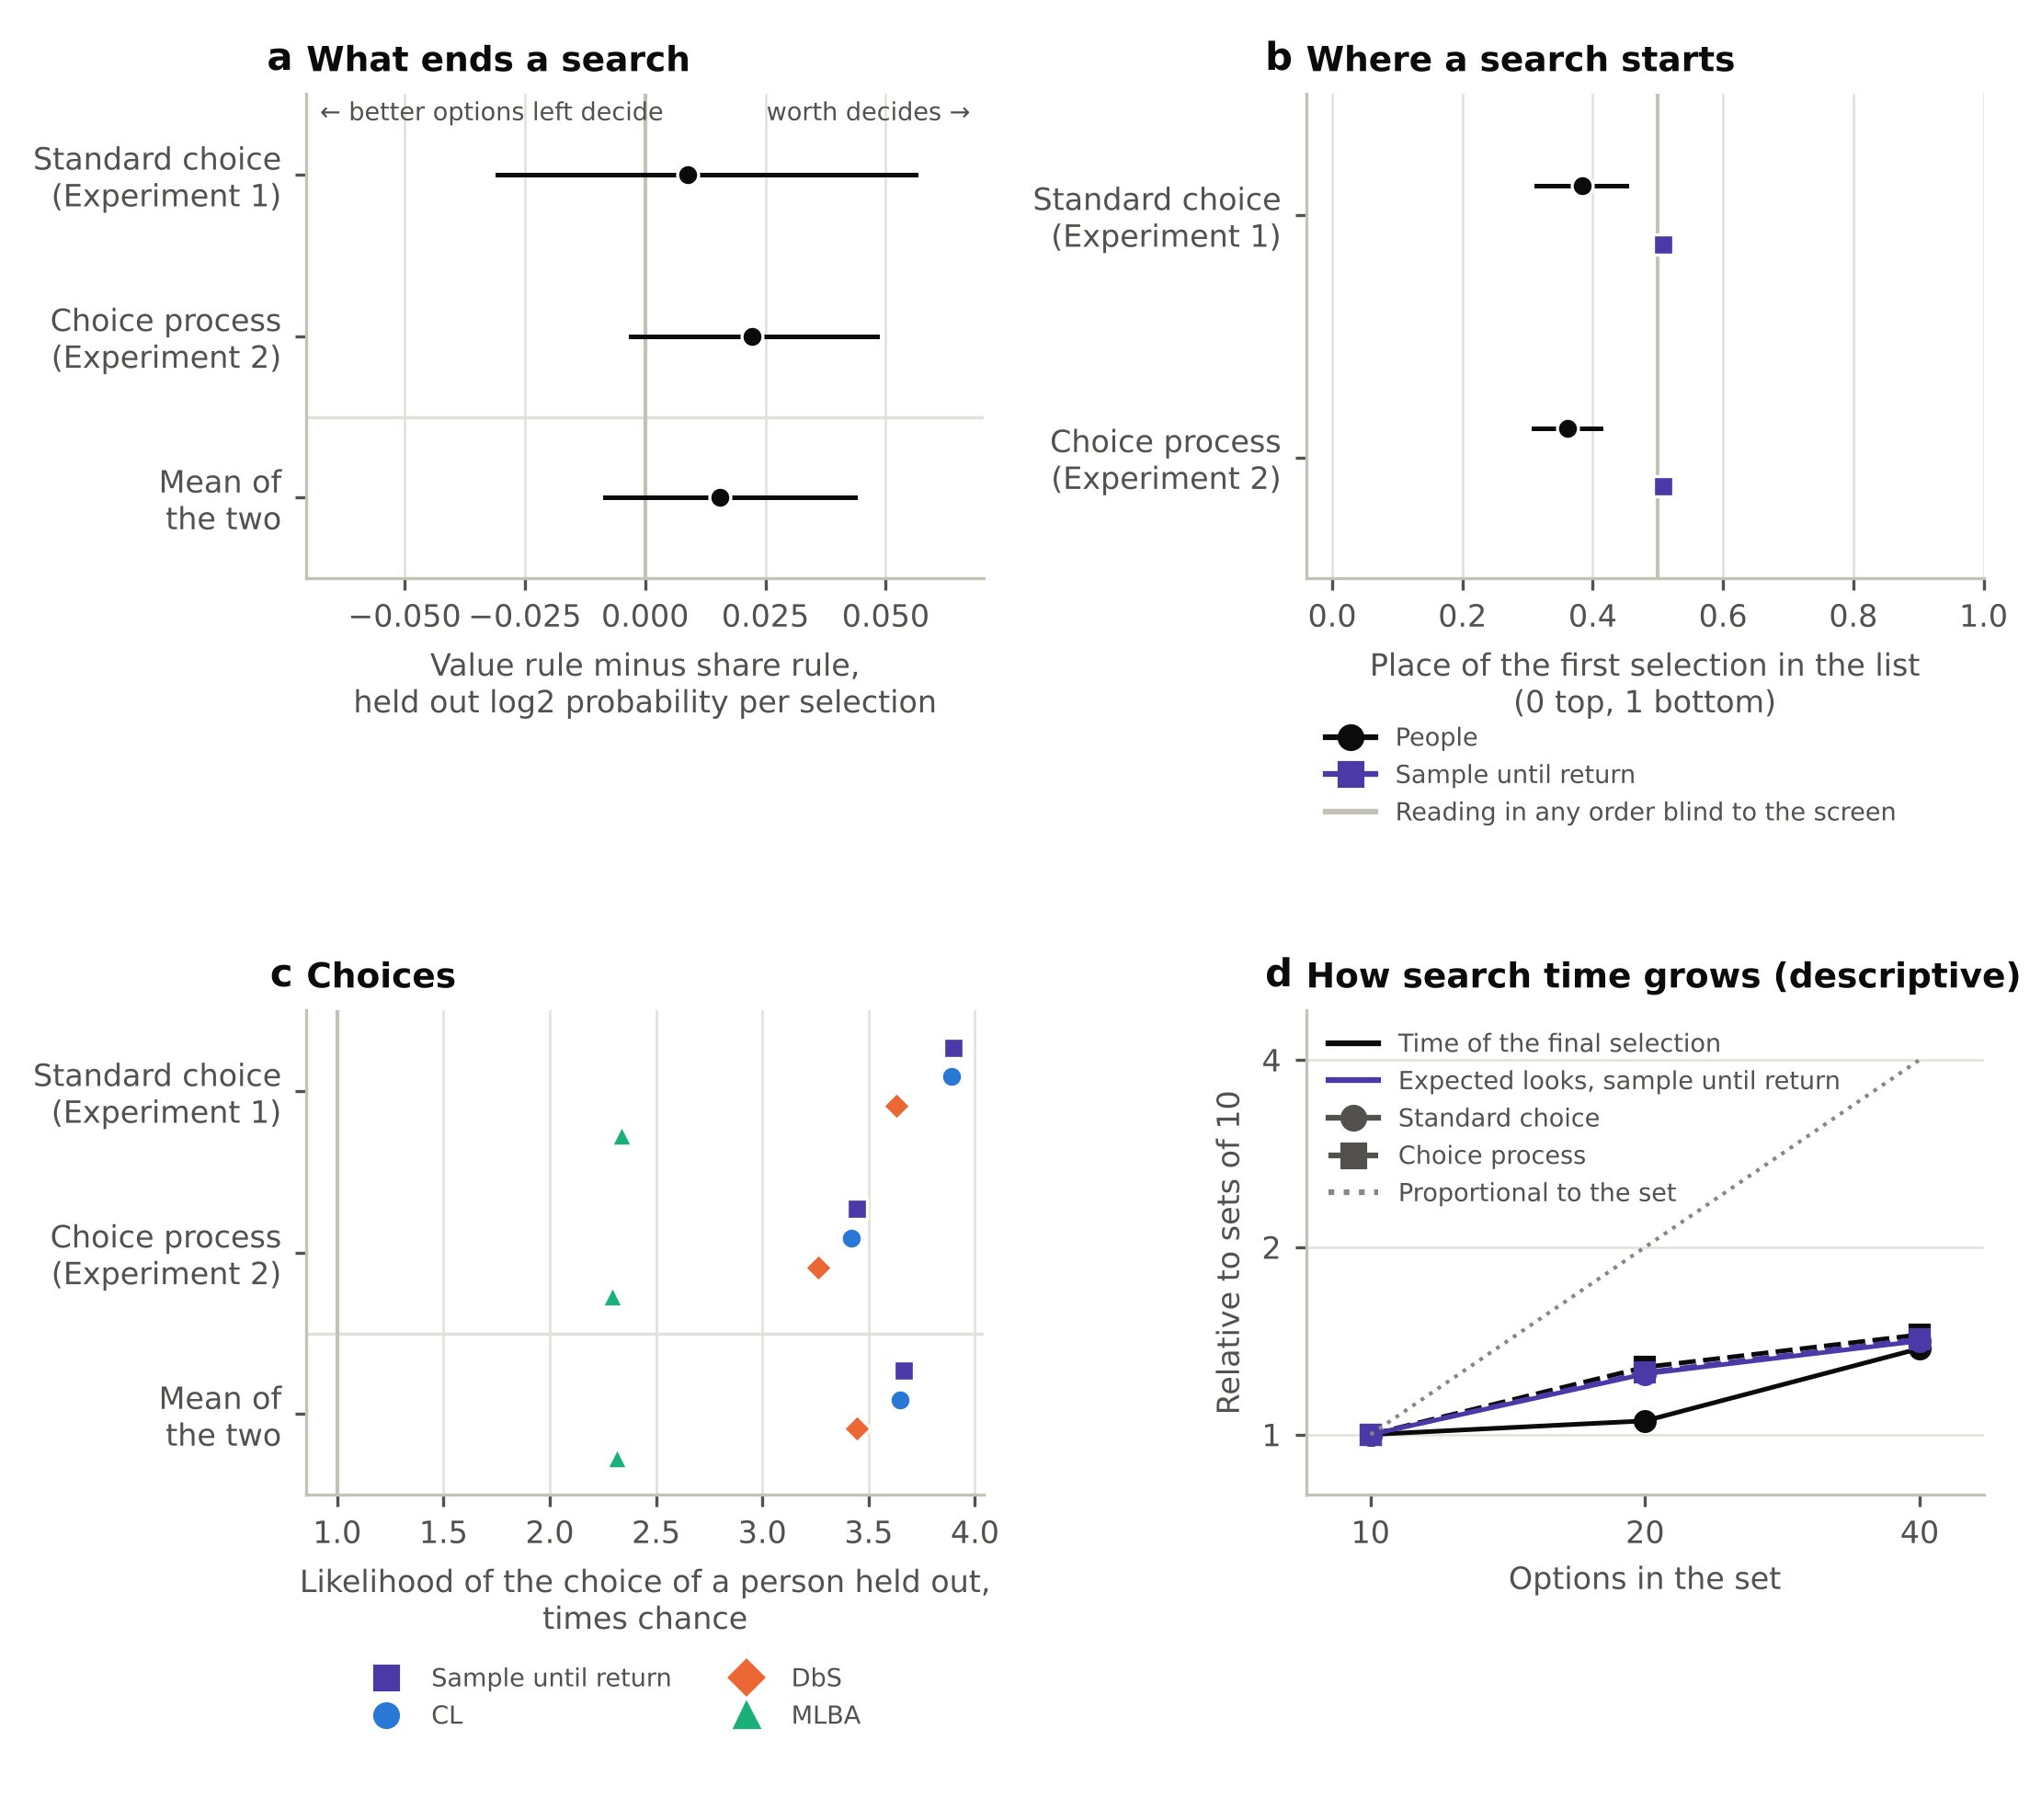

# The search model's stopping rule on the data of Caplin, Dean and Martin (Amendment 7, confirmatory)

## Decisions

- C1, stopping. Value rule minus share rule +0.0155 [-0.0083, 0.0437] bits per selection. Verdict undecided.
- C2, order of search (Experiment 2). First selection's place 0.361 [0.309, 0.412] *, minus one half -0.139 [-0.191, -0.088] *, minus the model's -0.146 [-0.198, -0.096] *. Order matters True.
- C3, choices. Sample until return minus CL +0.41 [-0.06, 0.84] percent. Non inferior within 2 percent True, better False, worse False. Supported True.

## Mean of the two experiments

| Measure | Value |
|---|---|
| Stopping, value rule, log2 probability per selection | -0.7496 [-3.1697, -0.6975] |
| Stopping, share rule, log2 probability per selection | -0.7651 [-3.1963, -0.7051] |
| Stopping, value_time rule, log2 probability per selection | -0.7497 [-3.1699, -0.6960] |
| Stopping, share_time rule, log2 probability per selection | -0.7640 [-3.1857, -0.6972] |
| Stopping, value minus share | +0.0155 [-0.0083, 0.0437] |
| Stopping, value minus share, time in both | +0.0143 [-0.0250, 0.0422] |
| Growth of the final selection time with set size (elasticity) | +0.27 [0.17, 0.36] * |
| Growth of the model's expected looks (elasticity) | +0.23 [0.20, 0.26] * |
| Choices, times chance, CL, DbS, MLBA, SR | 3.648, 3.443, 2.316, 3.663 |
| Choices, SR minus CL, percent | +0.41 [-0.06, 0.84] |
| Choices, SR minus DbS, percent | +6.38 [-2.66, 18.47] |
| Choices, SR minus MLBA, percent | +58.19 [43.95, 76.62] * |
| Time error, static law (number of options) | 0.805 [0.757, 0.865] * |
| Time error, SR's expected looks | 0.810 [0.764, 0.870] * |
| Time error, SR minus static | +0.0053 [-0.0041, 0.0173] |

## Experiment 1, standard choice

| Measure | Value |
|---|---|
| Stopping, value rule, log2 probability per selection | -0.8296 [-5.6175, -0.7276] |
| Stopping, share rule, log2 probability per selection | -0.8384 [-5.6449, -0.7255] |
| Stopping, value_time rule, log2 probability per selection | -0.8637 [-5.6488, -0.7560] |
| Stopping, share_time rule, log2 probability per selection | -0.8713 [-5.6631, -0.7411] |
| Stopping, value minus share | +0.0088 [-0.0306, 0.0563] |
| Stopping, value minus share, time in both | +0.0077 [-0.0681, 0.0573] |
| First selection's place (0 top, 1 bottom) | 0.384 [0.313, 0.452] * |
| The model's predicted place | 0.507 [0.505, 0.511] * |
| Growth of the final selection time with set size (elasticity) | +0.29 [0.16, 0.41] * |
| Growth of the model's expected looks (elasticity) | +0.23 [0.18, 0.28] * |
| Final selection time at 10, 20 and 40 options, seconds | 32.9, 34.6, 45.2 |
| The model's expected looks at 10, 20 and 40 options | 3.9, 4.9, 5.5 |
| Choices, times chance, CL, DbS, MLBA, SR | 3.891, 3.632, 2.339, 3.897 |
| Choices, SR minus CL, percent | +0.16 [-0.57, 0.78] |
| Choices, SR minus DbS, percent | +7.30 [-7.42, 31.22] |
| Choices, SR minus MLBA, percent | +66.59 [42.83, 99.36] * |
| Time error, static law (number of options) | 0.779 [0.700, 0.887] * |
| Time error, SR's expected looks | 0.780 [0.707, 0.889] * |
| Time error, SR minus static | +0.0012 [-0.0125, 0.0210] |

## Experiment 2, choice process

| Measure | Value |
|---|---|
| Stopping, value rule, log2 probability per selection | -0.6697 [-0.7730, -0.5993] * |
| Stopping, share rule, log2 probability per selection | -0.6919 [-0.8159, -0.6068] * |
| Stopping, value_time rule, log2 probability per selection | -0.6357 [-0.7523, -0.5694] * |
| Stopping, share_time rule, log2 probability per selection | -0.6566 [-0.7925, -0.5778] * |
| Stopping, value minus share | +0.0223 [-0.0031, 0.0482] |
| Stopping, value minus share, time in both | +0.0209 [-0.0055, 0.0442] |
| First selection's place (0 top, 1 bottom) | 0.361 [0.309, 0.412] * |
| The model's predicted place | 0.508 [0.505, 0.511] * |
| Growth of the final selection time with set size (elasticity) | +0.24 [0.10, 0.38] * |
| Growth of the model's expected looks (elasticity) | +0.24 [0.19, 0.27] * |
| Final selection time at 10, 20 and 40 options, seconds | 14.3, 18.3, 20.6 |
| The model's expected looks at 10, 20 and 40 options | 4.0, 5.0, 5.6 |
| Choices, times chance, CL, DbS, MLBA, SR | 3.420, 3.265, 2.292, 3.443 |
| Choices, SR minus CL, percent | +0.66 [0.05, 1.17] * |
| Choices, SR minus DbS, percent | +5.47 [-3.55, 15.18] |
| Choices, SR minus MLBA, percent | +50.22 [33.53, 68.54] * |
| Time error, static law (number of options) | 0.830 [0.782, 0.886] * |
| Time error, SR's expected looks | 0.840 [0.791, 0.895] * |
| Time error, SR minus static | +0.0093 [-0.0015, 0.0249] |

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero.


In [16]:
from overload.experiments import stopping_cdm
from overload.figures import figure_stopping_cdm
out = REPO / "results" / "stopping_cdm"
if RECOMPUTE or not (out / "summary.json").exists():
    # the data need a free openICPSR sign in, see data/README.md and scripts/prepare_cdm_data.sh
    stopping_cdm.run(REPO / "data" / "cdm", out, replicates=1000, jobs=JOBS)
stop = json.loads((out / "summary.json").read_text())
figure_stopping_cdm(stop, out / "fig_stopping_cdm")
display(Image(filename=str(out / "fig_stopping_cdm.png"), width=900))
display(Markdown((out / "table_stopping_cdm.md").read_text()))


**Findings.**

1. **What ends a search was undecided (C1).** The worth of a selection forecast its being the last no better than the share of better options left (+0.016 bits [-0.008, 0.044]). Both experiments leaned toward the worth, neither clearly. The test could hardly ever favor the model's first return, as stated before the run, so this does not count against it, and it does not show the clear satisficing the original paper suggested either.
2. **Search started high on the list (C2).** The first selection sat at 0.36 of the way down [0.31, 0.41], against one half for any order blind to the screen and 0.51 for the model. When values must be worked out, people partly read from the top, which attention drawn by value does not capture.
3. **Choices matched CL (C3)**, +0.4 percent [-0.1, 0.8], and beat MLBA by 58 percent.
4. Descriptive. The time of the final selection grew with the set size about as fast as the model's expected looks (elasticity 0.27 against 0.23). Up to 20 percent of complex rounds in Experiment 2 were never submitted.

**Message.** The model's choices hold on a fifth dataset, now money worked out from arithmetic, but its attention misses that such search follows the screen.

**Verification.** A second run reproduced every value. The independent implementation, written blind from `verification/VERIFY_BRIEF_CDM.md`, agreed on every decision and value (one interval end of a descriptive differed by 4e-8 relative). `sh verification/run_independent_cdm.sh` reruns it.


In [17]:
r = subprocess.run([sys.executable, "verification/compare_stopping_cdm.py",
                    "--independent", "verification/independent_cdm/results.json",
                    "--results", "results/stopping_cdm"], cwd=REPO, capture_output=True, text=True)
print(r.stdout[-1500:] or r.stderr[-1500:])


Independent reimplementation against the package, stopping tests on the data of Caplin, Dean and Martin

Kind            checked   largest difference
choices              21   2.66e-07
clear                56   0
decision              7   0
descriptive          12   0
first selection       8   5.32e-11
growth               24   1.9e-08
interval            224   1.19e-06
p value              56   0
parameter            80   5.07e-09
stopping             18   1.11e-16
time                  9   3.6e-09

1 values outside tolerance:
  interval       standard SR_minus_DbS_percent percentile[1]: package 31.221344652756542 independent 31.221343463158835 (diff 1.19e-06)



## 13. Confirmatory. Can the models forecast choice overload? (Amendment 8)

**Question.** Choice overload means that more options make choices worse. With every option's value known, a choice is worse when it misses the best option on display, so overload is the growth of misses with set size. Before people choose, can a model foresee how much worse choices get in a set size it has never seen, and on which trials?

**Why it matters.** This is the premonition the paper set out to deliver, tested where it can be checked against what people did.

**What motivated the test (exploratory, snack data).** Every fixed model foresaw misses rising with set size, while people's stayed near 20 percent. CL whose sensitivity rises with set size at the rate found by H1 (compensation) foresaw the flat line. People compensated when a snack could be judged at a glance. The frozen claim was that compensation needs cheap judging, so overload should appear where values must be worked out (Caplin, Dean and Martin) or a choice made in three seconds (Reutskaja and colleagues, eye tracking, sets of 4, 9 and 16).

**How.**
- O1, overload. People's growth of misses (per doubling of the set) against each model's forecast, every set size forecast from fits to the others. Overload when misses grow clearly more than compensation foresees, compensation when clearly less than CL foresees.
- O2, premonition. Within a set size, whether sample until return's forecast picks out the trials with a miss better than the count of options near the best (area under the curve).
- Frozen in Amendment 8 with Amendment 7, run once, verified twice. The snack data and DbS and MLBA are exploratory.


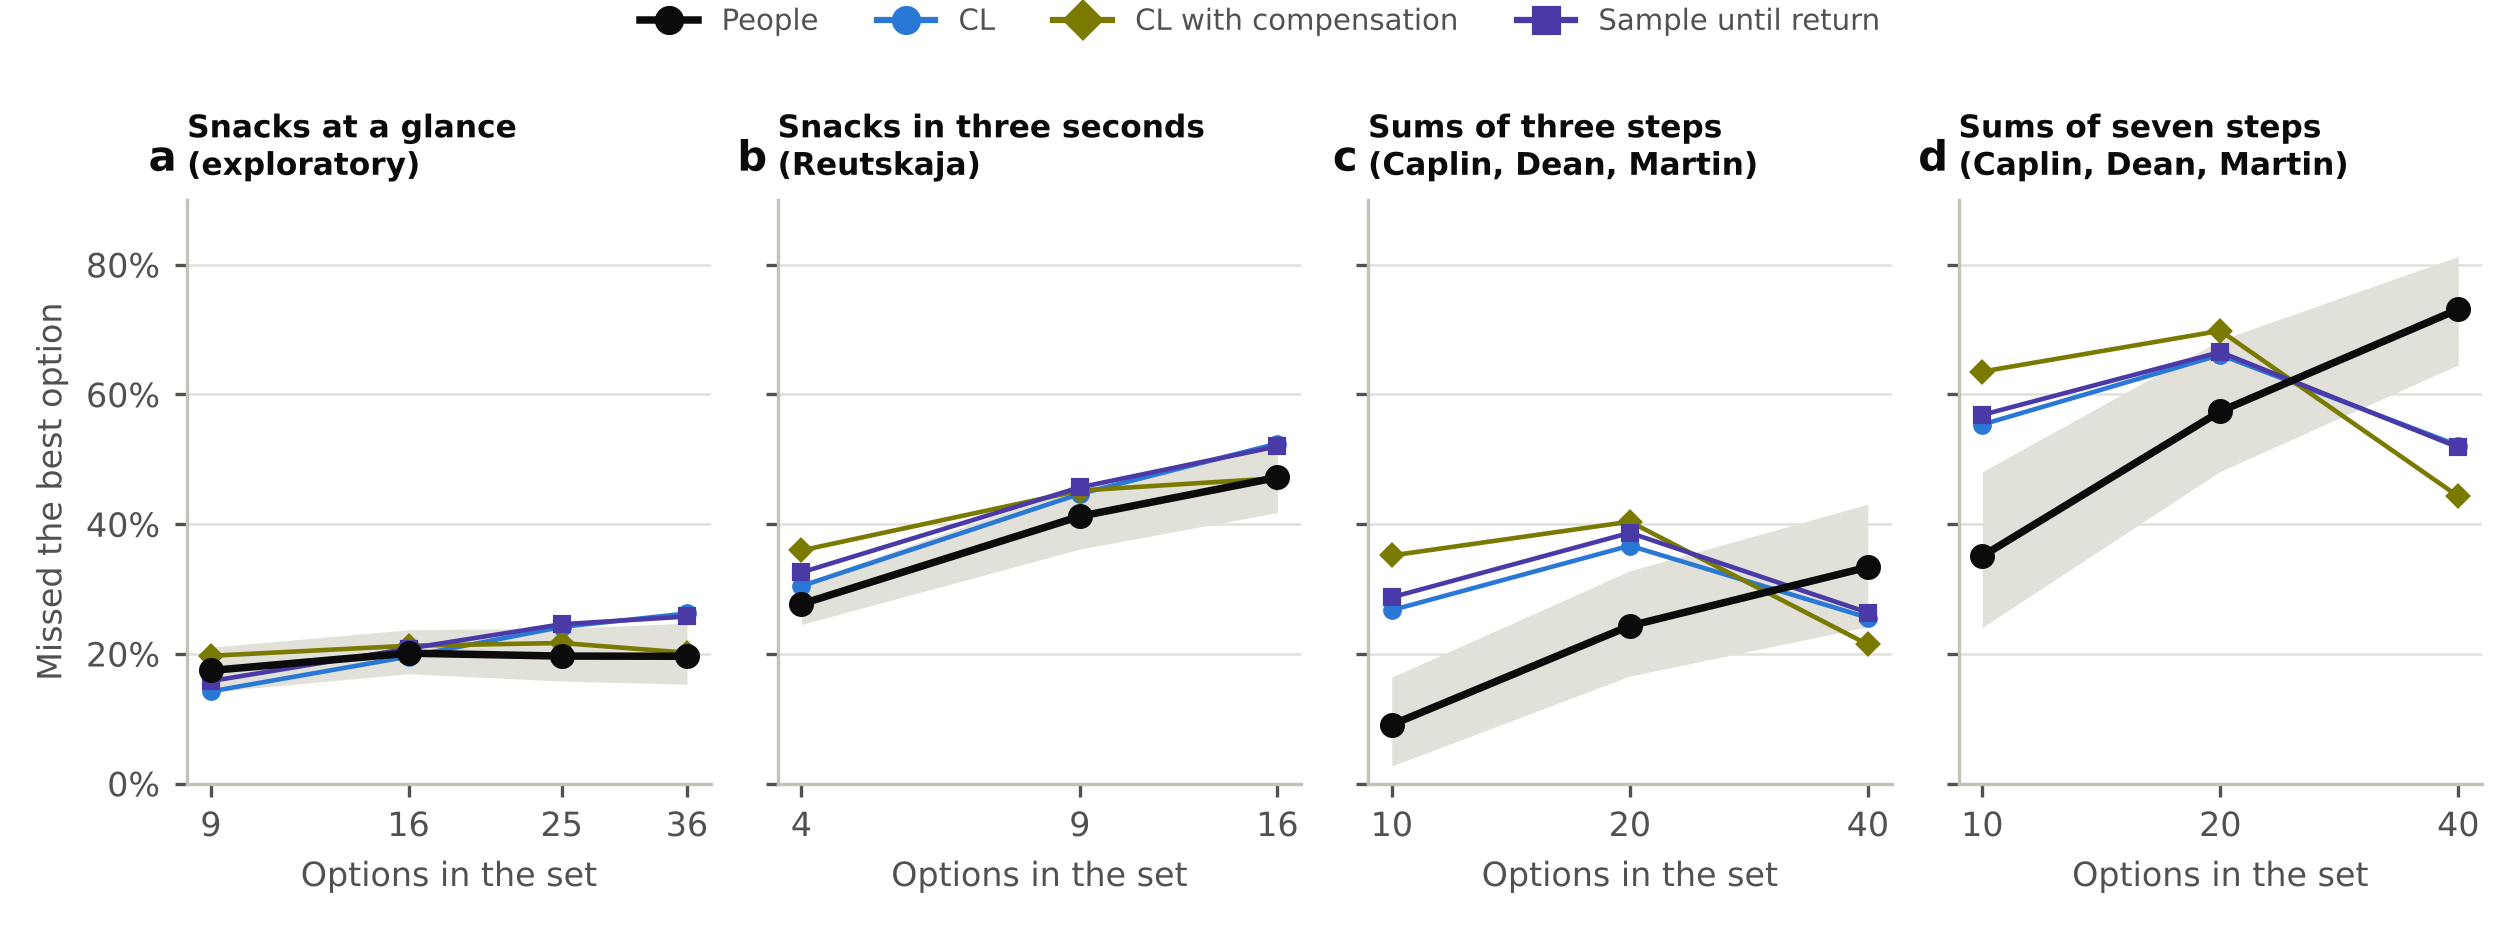

# Forecasting choice overload (Amendment 8)

## cdm

| Measure | Value |
|---|---|
| Growth of misses per doubling of the set, observed | +0.156 [0.126, 0.183] * |
| Growth of misses per doubling of the set, CL | -0.011 [-0.022, 0.002] |
| Growth of misses per doubling of the set, CL_comp | -0.082 [-0.094, -0.067] * |
| Growth of misses per doubling of the set, SR | -0.018 [-0.030, -0.006] * |
| Error of the forecast growth, CL | 0.167 [0.129, 0.202] * |
| Error of the forecast growth, CL_comp | 0.238 [0.196, 0.272] * |
| Error of the forecast growth, SR | 0.174 [0.136, 0.209] * |
| O1, people's growth minus compensation's | +0.238 [0.196, 0.272] * |
| O1, people's growth minus CL's | +0.167 [0.129, 0.202] * |
| Compensation's error minus CL's (descriptive) | +0.071 [0.066, 0.075] * |
| O1 verdict | overload |
| Within set size, area under the curve, CL | 0.554 [0.521, 0.593] * |
| Within set size, area under the curve, CL_comp | 0.553 [0.520, 0.591] * |
| Within set size, area under the curve, SR | 0.554 [0.521, 0.594] * |
| Within set size, area under the curve, near_best | 0.561 [0.536, 0.590] * |
| Within set size, area under the curve, minus_gap | 0.552 [0.524, 0.585] * |
| O2, SR minus the near best count | -0.007 [-0.029, 0.017] |
| SR minus one half (descriptive) | +0.054 [0.021, 0.094] * |
| O2 supported | False |

## reutskaja

| Measure | Value |
|---|---|
| Growth of misses per doubling of the set, observed | +0.099 [0.075, 0.122] * |
| Growth of misses per doubling of the set, CL | +0.111 [0.092, 0.128] * |
| Growth of misses per doubling of the set, CL_comp | +0.057 [0.038, 0.074] * |
| Growth of misses per doubling of the set, SR | +0.098 [0.080, 0.115] * |
| Error of the forecast growth, CL | 0.012 [0.001, 0.039] |
| Error of the forecast growth, CL_comp | 0.042 [0.015, 0.071] * |
| Error of the forecast growth, SR | 0.001 [0.001, 0.032] |
| O1, people's growth minus compensation's | +0.042 [0.015, 0.071] * |
| O1, people's growth minus CL's | -0.012 [-0.039, 0.018] |
| Compensation's error minus CL's (descriptive) | +0.030 [-0.024, 0.055] |
| O1 verdict | overload |
| Within set size, area under the curve, CL | 0.702 [0.674, 0.730] * |
| Within set size, area under the curve, CL_comp | 0.701 [0.672, 0.729] * |
| Within set size, area under the curve, SR | 0.702 [0.675, 0.731] * |
| Within set size, area under the curve, near_best | 0.609 [0.585, 0.632] * |
| Within set size, area under the curve, minus_gap | 0.599 [0.577, 0.619] * |
| O2, SR minus the near best count | +0.093 [0.073, 0.116] * |
| SR minus one half (descriptive) | +0.202 [0.175, 0.231] * |
| O2 supported | True |

## Miss rates by set size (original sample)

- cdm_standard_3, sizes [10, 20, 40]
  - observed: 0.068, 0.220, 0.288
  - CL: 0.257, 0.358, 0.241
  - CL_comp: 0.341, 0.399, 0.202
  - SR: 0.278, 0.381, 0.249
- cdm_standard_7, sizes [10, 20, 40]
  - observed: 0.236, 0.561, 0.654
  - CL: 0.533, 0.638, 0.471
  - CL_comp: 0.619, 0.678, 0.399
  - SR: 0.549, 0.644, 0.471
- cdm_process_3, sizes [10, 20, 40]
  - observed: 0.114, 0.267, 0.379
  - CL: 0.278, 0.376, 0.271
  - CL_comp: 0.362, 0.409, 0.226
  - SR: 0.296, 0.392, 0.278
- cdm_process_7, sizes [10, 20, 40]
  - observed: 0.465, 0.587, 0.809
  - CL: 0.574, 0.684, 0.571
  - CL_comp: 0.652, 0.718, 0.486
  - SR: 0.588, 0.686, 0.566
- reutskaja, sizes [4, 9, 16]
  - observed: 0.277, 0.412, 0.472
  - CL: 0.305, 0.447, 0.524
  - CL_comp: 0.359, 0.452, 0.471
  - SR: 0.326, 0.457, 0.520
  - misses whose best option was never fixated: 0.248, 0.568, 0.636

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero.


Exploratory, all five models

# Forecasting choice overload (Amendment 8)

## cdm

| Measure | Value |
|---|---|
| Growth of misses per doubling of the set, observed | +0.156 [0.126, 0.183] * |
| Growth of misses per doubling of the set, CL | -0.011 [-0.022, 0.002] |
| Growth of misses per doubling of the set, CL_comp | -0.082 [-0.094, -0.067] * |
| Growth of misses per doubling of the set, SR | -0.018 [-0.030, -0.006] * |
| Growth of misses per doubling of the set, DbS | +0.234 [0.217, 0.244] * |
| Growth of misses per doubling of the set, MLBA | +0.215 [0.201, 0.229] * |
| Error of the forecast growth, CL | 0.167 [0.129, 0.202] * |
| Error of the forecast growth, CL_comp | 0.238 [0.196, 0.272] * |
| Error of the forecast growth, SR | 0.174 [0.136, 0.209] * |
| Error of the forecast growth, DbS | 0.080 [0.064, 0.119] * |
| Error of the forecast growth, MLBA | 0.061 [0.049, 0.100] * |
| O1, people's growth minus compensation's | +0.238 [0.196, 0.272] * |
| O1, people's growth minus CL's | +0.167 [0.129, 0.202] * |
| Compensation's error minus CL's (descriptive) | +0.071 [0.066, 0.075] * |
| O1 verdict | overload |
| Within set size, area under the curve, CL | 0.554 [0.521, 0.593] * |
| Within set size, area under the curve, CL_comp | 0.553 [0.520, 0.591] * |
| Within set size, area under the curve, SR | 0.554 [0.521, 0.594] * |
| Within set size, area under the curve, DbS | 0.525 [0.490, 0.558] * |
| Within set size, area under the curve, MLBA | 0.514 [0.482, 0.551] * |
| Within set size, area under the curve, near_best | 0.561 [0.536, 0.590] * |
| Within set size, area under the curve, minus_gap | 0.552 [0.524, 0.585] * |
| O2, SR minus the near best count | -0.007 [-0.029, 0.017] |
| SR minus one half (descriptive) | +0.054 [0.021, 0.094] * |
| O2 supported | False |

## reutskaja

| Measure | Value |
|---|---|
| Growth of misses per doubling of the set, observed | +0.099 [0.075, 0.122] * |
| Growth of misses per doubling of the set, CL | +0.111 [0.092, 0.128] * |
| Growth of misses per doubling of the set, CL_comp | +0.057 [0.038, 0.074] * |
| Growth of misses per doubling of the set, SR | +0.098 [0.080, 0.115] * |
| Growth of misses per doubling of the set, DbS | +0.208 [0.184, 0.231] * |
| Growth of misses per doubling of the set, MLBA | +0.209 [0.187, 0.231] * |
| Error of the forecast growth, CL | 0.012 [0.001, 0.039] |
| Error of the forecast growth, CL_comp | 0.042 [0.015, 0.071] * |
| Error of the forecast growth, SR | 0.001 [0.001, 0.032] |
| Error of the forecast growth, DbS | 0.109 [0.074, 0.142] * |
| Error of the forecast growth, MLBA | 0.111 [0.079, 0.142] * |
| O1, people's growth minus compensation's | +0.042 [0.015, 0.071] * |
| O1, people's growth minus CL's | -0.012 [-0.039, 0.018] |
| Compensation's error minus CL's (descriptive) | +0.030 [-0.024, 0.055] |
| O1 verdict | overload |
| Within set size, area under the curve, CL | 0.702 [0.674, 0.730] * |
| Within set size, area under the curve, CL_comp | 0.701 [0.672, 0.729] * |
| Within set size, area under the curve, SR | 0.702 [0.675, 0.731] * |
| Within set size, area under the curve, DbS | 0.637 [0.604, 0.676] * |
| Within set size, area under the curve, MLBA | 0.582 [0.541, 0.629] * |
| Within set size, area under the curve, near_best | 0.609 [0.585, 0.632] * |
| Within set size, area under the curve, minus_gap | 0.599 [0.577, 0.619] * |
| O2, SR minus the near best count | +0.093 [0.073, 0.116] * |
| SR minus one half (descriptive) | +0.202 [0.175, 0.231] * |
| O2 supported | True |

## Miss rates by set size (original sample)

- cdm_standard_3, sizes [10, 20, 40]
  - observed: 0.068, 0.220, 0.288
  - CL: 0.257, 0.358, 0.241
  - CL_comp: 0.341, 0.399, 0.202
  - SR: 0.278, 0.381, 0.249
  - DbS: 0.079, 0.322, 0.620
  - MLBA: 0.456, 0.770, 0.916
- cdm_standard_7, sizes [10, 20, 40]
  - observed: 0.236, 0.561, 0.654
  - CL: 0.533, 0.638, 0.471
  - CL_comp: 0.619, 0.678, 0.399
  - SR: 0.549, 0.644, 0.471
  - DbS: 0.403, 0.653, 0.814
  - MLBA: 0.510, 0.779, 0.922
- cdm_process_3, sizes [10, 20, 40]
  - observed: 0.114, 0.267, 0.379
  - CL: 0.278, 0.376, 0.271
  - CL_comp: 0.362, 0.409, 0.226
  - SR: 0.296, 0.392, 0.278
  - DbS: 0.082, 0.272, 0.637
  - MLBA: 0.422, 0.731, 0.913
- cdm_process_7, sizes [10, 20, 40]
  - observed: 0.465, 0.587, 0.809
  - CL: 0.574, 0.684, 0.571
  - CL_comp: 0.652, 0.718, 0.486
  - SR: 0.588, 0.686, 0.566
  - DbS: 0.497, 0.736, 0.861
  - MLBA: 0.574, 0.809, 0.933
- reutskaja, sizes [4, 9, 16]
  - observed: 0.277, 0.412, 0.472
  - CL: 0.305, 0.447, 0.524
  - CL_comp: 0.359, 0.452, 0.471
  - SR: 0.326, 0.457, 0.520
  - DbS: 0.190, 0.481, 0.600
  - MLBA: 0.254, 0.554, 0.666
  - misses whose best option was never fixated: 0.248, 0.568, 0.636

Brackets give 95% percentile intervals from 1000 participant resamples. A star marks a value whose percentile and basic intervals both exclude zero.


In [18]:
from overload.experiments import overload_premonition
from overload.figures import figure_overload_forecast
out = REPO / "results" / "overload_premonition"
if RECOMPUTE or not (out / "summary.json").exists():
    overload_premonition.run({"cdm": REPO / "data" / "cdm", "reutskaja": REPO / "data" / "reutskaja"}, out,
                             replicates=1000, jobs=JOBS, status="confirmatory, Amendment 8")
over = json.loads((out / "summary.json").read_text())
snack_over = json.loads((REPO / "results" / "overload_snack" / "summary.json").read_text())  # exploratory
figure_overload_forecast(over, snack_over, out / "fig_overload_forecast")
display(Image(filename=str(out / "fig_overload_forecast.png"), width=950))
display(Markdown((out / "table_overload.md").read_text()))
display(Markdown("Exploratory, all five models\n\n" + (REPO / "results" / "overload_all_models" / "table_overload.md").read_text()))


**Findings.**

1. **Snacks at a glance, no overload (exploratory).** Misses grew by +0.010 per doubling [-0.003, 0.026]. CL foresaw +0.062 and sample until return +0.051, compensation +0.004. People compensated.
2. **Snacks in three seconds, overload, and the model foresaw it.** Misses rose from 28 to 47 percent between 4 and 16 snacks (+0.099 per doubling). Sample until return foresaw +0.098 and CL +0.111, compensation too little (+0.057), so the verdict is overload (O1). Within a set size, the model picked out the trials with a miss at 0.70, against 0.61 for the near best count (+0.093 [0.073, 0.116], O2 supported). Most of the extra misses were snacks never looked at (25 percent of misses at 4 snacks, 64 percent at 16).
3. **Sums worked out, overload beyond every forecast.** Misses rose from 9 to 33 percent (three steps) and from 35 to 73 percent (seven steps) between 10 and 40 options (+0.156 per doubling), while every value based model foresaw flat or falling misses (CL -0.011, sample until return -0.018). The verdict is overload, beyond even fixed sensitivity. Trial by trial no forecast told the misses apart (about 0.55 for all, O2 not supported).
4. **Exploratory, DbS and MLBA.** Comparing options by rank, they foresaw misses growing in the sums (+0.23 and +0.22), closest to people, but at levels far too high (MLBA up to 92 percent), and twice too much growth in the three second snacks.

**Message.** People compensate for more options when an option can be judged at a glance, and choice overload appears when judging is costly. When the cost is time, the search model forecasts overload, both how much worse choices get with more options and on which trials. When the cost is working out the values, misses grow for reasons the values do not show, and no model that sees only the values foresees them.

**Verification.** A second run reproduced every value, and the independent implementation, written blind from `verification/VERIFY_BRIEF_OVERLOAD.md`, agreed on every value and decision (largest difference 2e-8). `sh verification/run_independent_overload.sh` reruns it.


In [19]:
r = subprocess.run([sys.executable, "verification/compare_overload.py",
                    "--independent", "verification/independent_overload/results.json",
                    "--results", "results/overload_premonition"], cwd=REPO, capture_output=True, text=True)
print(r.stdout[-1500:] or r.stderr[-1500:])


Independent reimplementation against the package, forecasting choice overload

Kind            checked   largest difference
auc                  14   0
clear                34   0
decision             10   0
growth               20   3.02e-09
interval            136   9.21e-09
p value              34   0
parameter            45   7.07e-09
rates                63   1.52e-08

Every value agrees within tolerance.



## 14. Where the search model stands

- **Choices.** On five open datasets, sample until return predicted the choices of people it had not seen as well as CL, the best established model, and clearly better than MLBA.
- **Search.** On the snack data, the number of options people looked at grew like the square root of what was on offer, as the model predicted before it saw these data.
- **Slow decisions.** In every dataset with times, within each person, the decisions the model expected to need more looks took longer.
- **Choice overload.** People compensated for more options when snacks could be judged at a glance. When choices had to be made in three seconds, the model forecast how much worse they got and on which trials. When values had to be worked out, overload outgrew every model's forecast.
- **Felt overload.** On the development data, decision time tracked how overloaded people felt, while missing the best option barely did, so the open datasets speak to overload in choice quality.
- **Limits.** No model times single decisions much better than a constant. An absolute standard (two look satisficing) failed its test, and where values must be worked out, search follows the screen rather than value.
